# Этап 1 (п. 1.1 плана). Граф переходов: вариант «OldCase (главный вариант)»

Ноутбук строит граф переходов между типами преступлений по таблице этапа 0 `compas_custody_charges.csv` шаг за шагом: эпизоды → журнал событий PM4Py → матрица переходов → графы (DFG, Heuristics Miner, Inductive Miner) → от чего зависит следующее состояние. После каждого важного шага числа сверяются с сохранёнными результатами варианта (`results`).

**Правило этого варианта (главный, решение от 09.10).** Обвинения по делам, которые уже встречались у человека в прошлом эпизоде, — *старые*. Если в эпизоде есть хоть одно новое обвинение, старые не учитываются (состояние = типы новых). Если все обвинения старые, эпизод получает отдельное состояние **`OldCase`** — «вернулся в заключение по прежнему делу». Событий столько же, сколько в варианте «все новые», но самопереходы из-за старых дел уходят в `OldCase`.

**Варианты работы с повторными заключениями** (у каждого своя папка в `stage1/`):
| Вариант (папка) | Обвинение по старому делу в смешанном эпизоде | Эпизод только из старых дел |
|---|---|---|
| все новые (`stage1/all_new`) | считается как новое | состояние = типы его обвинений |
| OldCase (`stage1/oldcase`, главный) | не учитывается | отдельное состояние `OldCase` |
| без OldCase (`stage1/no_oldcase`) | не учитывается | эпизод убран из последовательности |
| склейка ±7 (`stage1/glue7`) | как «все новые» или «без OldCase» (флаг) | сначала склейка соседних заключений ≤ 7 дней с общей статьёй |
| категории ×2 (`stage1/oldcase_x2`, отдельная ветка) | — | состояние `OldCase: <тип>` |

*Старое обвинение* — его `case_number` уже встречался у этого же человека (`id`) в более раннем эпизоде.

**Общее для всех вариантов:** объект = человек (`id`), событие = заключение (custody), состояние = множество из 15 типов преступлений (несколько типов — развилка), перевод jail → prison в тот же день склеивается с предыдущим заключением, Justice идёт отдельным шагом после остальных типов эпизода, терминального состояния нет (последний эпизод человека цензурируется концом наблюдения 19.04.2016), модели учатся на 80% людей и проверяются на 20% (seed 42).

**Как запустить.** В PowerShell: `D:\Git\diploma\.venv\Scripts\activate`, затем `jupyter lab` в папке `D:\diploma\jupyter lab`, открыть `stage1/oldcase/stage1_oldcase.ipynb`, *Run → Run All Cells* (около минуты). Ноутбук **не перезаписывает** сохранённые результаты: всё пересчитанное он пишет в `notebook_out/`.

## Шаг 0. Настройки

- `DATA` — входная таблица этапа 0 (её строит ноутбук `stage0 - data/build_compas_custody_charges.ipynb`);
- `RES` — сохранённые результаты варианта, с ними сверяется пересчёт;
- `OUT` — папка, куда ноутбук пишет то, что пересчитал (`notebook_out/`);
- `RUN_MODELS` — строить сети Петри (IM, HM, DFG) на train, меньше минуты;
- `RUN_EVAL` — пересчитать fitness/precision для HM dep 0.9 (несколько минут). Для всех моделей это часы, поэтому таблица качества по умолчанию берётся из сохранённого файла.

Пути относительные: ноутбук запускается из своей папки. Окружение: `D:\Git\diploma\.venv` (pm4py 2.7, pandas, scikit-learn, graphviz). Если `dot` не найден, но есть `D:\Graphviz\bin`, папка добавляется в PATH; без Graphviz ноутбук покажет сохранённые рисунки.

In [1]:
import os, sys, time, shutil, warnings
from pathlib import Path

HERE = Path.cwd()                                   # папка ноутбука
DATA = HERE / ".." / ".." / "stage0 - data" / "out" / "compas_custody_charges.csv"
RES = HERE / "results"                              # сохранённые результаты варианта
OUT = HERE / "notebook_out"                         # сюда пишет ноутбук
OUT.mkdir(exist_ok=True)

RUN_MODELS = True    # сети Петри IM / HM / DFG на train
RUN_EVAL = False     # пересчёт fitness/precision для HM dep 0.9 (несколько минут)

if shutil.which("dot") is None and Path(r"D:\Graphviz\bin").exists():
    os.environ["PATH"] = r"D:\Graphviz\bin" + os.pathsep + os.environ["PATH"]

import numpy as np
import pandas as pd
import pm4py
from IPython.display import Image, display

warnings.filterwarnings("ignore")
sys.path.insert(0, str(HERE / "code"))
import stage1_common as base            # рисунок матрицы, V Крамера, оценка моделей
from crime_categories import categorize_fine as categorize, UNKNOWN

pd.set_option("display.max_columns", 40, "display.width", 200)
print("pm4py", pm4py.__version__, "| pandas", pd.__version__)
print("таблица этапа 0:", DATA.resolve(), "| есть:", DATA.exists())
print("Graphviz:", "есть" if shutil.which("dot") else "НЕТ (будут показаны сохранённые рисунки)")


def show(path, width=None, max_px=1400):
    # показать рисунок; большие уменьшаются до max_px по длинной стороне (полный размер — в файле)
    from io import BytesIO
    from PIL import Image as PILImage
    im = PILImage.open(path)
    if max(im.size) > max_px:
        im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=85)
    display(Image(data=buf.getvalue(), format="jpeg", width=width))


def graphviz_ok():
    return shutil.which("dot") is not None



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | pandas 3.0.5
таблица этапа 0: /tmp/claude-0/w/jl/stage0 - data/out/compas_custody_charges.csv | есть: True
Graphviz: НЕТ (будут показаны сохранённые рисунки)


Константы те же, что в исходном скрипте варианта (`code/`):
- `PLACEHOLDER_OUT = 2020-01-01` — так в compas.db помечен выход «ещё в заключении», заменяется на конец наблюдения;
- `DEGREE_RANK` — тяжесть обвинения (F1 самое тяжёлое … MO3), для класса Felony / Misdemeanor;
- `DUR_BINS` — классы длительности заключения (для анализа причин перехода).

In [2]:
SEED = base.SEED          # 42
START = base.START        # "START" — фиктивное начальное состояние
CASE = "id"               # объект процесса = человек (person_id из compas.db)
MERGE = True              # склейка jail -> prison в тот же день
OLDCASE = "OldCase"
JUSTICE = "Justice"
PLACEHOLDER_OUT = pd.Timestamp("2020-01-01")
DEGREE_RANK = {"F1": 1, "F2": 2, "F3": 3, "F5": 4, "F6": 4, "F7": 4, "M1": 5, "M2": 6, "MO3": 7}
DEG = {1: "F", 2: "F", 3: "F", 4: "F", 5: "M", 6: "M", 7: "M"}
DUR_BINS = [-np.inf, 1, 30, 180, np.inf]
DUR_LABELS = ["S1_<=1d", "S2_2-30d", "S3_31-180d", "S4_>180d"]


def degree_rank(d):
    return DEGREE_RANK.get(str(d).strip("()"), 8)

## Шаг 1. Входные данные и 15 типов преступлений

Таблица этапа 0: одна строка = одно обвинение внутри заключения (`custody_num`); заключения = `jailhistory` + `prisonhistory` с 01.01.2013; `case_number` — номер дела (по нему определяются старые обвинения), `custody_source` — jail или prison; `charge_num = 0` — для заключения не нашлось обвинения (тип Unknown).

`crime_categories.categorize_fine` переводит текст обвинения `c_charge_desc` в тип по регулярным выражениям (срабатывает первое совпавшее правило). Типы: Violent, Property, Drug, Traffic, Weapon, Fraud, Sex, NoCharge, ResistPolice, PublicOrder, Tampering, Justice, Conspiracy, Minors, Other и Unknown.

In [3]:
raw = pd.read_csv(DATA, parse_dates=["in_custody", "out_custody"], low_memory=False)
print(f"строк (обвинений): {len(raw):,}; заключений: {raw.groupby(['id', 'custody_num']).ngroups:,}; людей: {raw['id'].nunique():,}")
raw.head()

строк (обвинений): 65,363; заключений: 22,552; людей: 10,580


,id,age,sex,race,c_charge_degree,c_charge_desc,in_custody,out_custody,custody_num,time_to_last_custody,time_since_last_arrest,time_to_future_arrest,event,event_of_future_arrest,curr_dur_custody,sum_dur_custody,average_dur_custody,all_future_arrest_times,all_future_events,charge_num,n_charges,charge_category,charge_source,case_number,custody_source
0,1,69,Male,Other,(F3),Aggravated Assault w/Firearm,2013-08-13,2013-08-14,1,NaN,NaN,328.0,1,1,1,0,NaN,[328],"[1, 0]",1,2,Violent,arrest,13011352CF10A,jail
1,1,69,Male,Other,(M1),Battery,2013-08-13,2013-08-14,1,NaN,NaN,328.0,1,1,1,0,NaN,[328],"[1, 0]",2,2,Violent,arrest,13011352CF10A,jail
2,1,69,Male,Other,(F3),Aggravated Assault w/Firearm,2014-07-07,2014-07-14,2,328.0,327.0,NaN,0,0,7,1,1.0,NaN,[0],1,2,Violent,arrest,13011352CF10A,jail
3,1,69,Male,Other,(M1),Battery,2014-07-07,2014-07-14,2,328.0,327.0,NaN,0,0,7,1,1.0,NaN,[0],2,2,Violent,arrest,13011352CF10A,jail
4,3,34,Male,African-American,(F3),Felony Battery w/Prior Convict,2013-01-26,2013-02-05,1,NaN,NaN,992.0,1,1,10,0,NaN,[992],"[1, 0]",1,1,Violent,arrest,13001275CF10A,jail


In [4]:
desc = raw["c_charge_desc"].value_counts()
mapping = pd.DataFrame({"rows": desc, "type": [categorize(d) for d in desc.index]})
by_type = mapping.groupby("type")["rows"].agg(charges="sum", wordings="size").sort_values("charges", ascending=False)
by_type["share"] = (by_type["charges"] / by_type["charges"].sum()).round(3)
print("разных формулировок:", len(mapping))
by_type

разных формулировок: 1417


,charges,wordings,share
type,,,
Traffic,16418,427,0.254
Property,13466,114,0.209
Drug,12976,271,0.201
Violent,9962,162,0.154
Fraud,4032,141,0.062
ResistPolice,3203,22,0.050
Sex,1396,66,0.022
PublicOrder,1216,111,0.019
Weapon,934,37,0.014


## Шаг 2. От обвинений к эпизодам

### 2.1. Загрузка
Каждому обвинению ставится тип и ранг тяжести; из обвинений собирается таблица заключений `ep` (одна строка = одно заключение в базе).

In [5]:
def load():
    ch = pd.read_csv(DATA, parse_dates=["in_custody", "out_custody"], low_memory=False)
    ch["type"] = ch["c_charge_desc"].map(categorize)
    ch.loc[ch["charge_num"] == 0, "type"] = UNKNOWN      # обвинение не найдено
    ch["rank"] = ch["c_charge_degree"].map(degree_rank)
    ep = (ch.sort_values(["id", "custody_num"])
            .groupby(["id", "custody_num"], as_index=False)
            .agg(in_custody=("in_custody", "first"), out_custody=("out_custody", "first"),
                 custody_source=("custody_source", "first"), age=("age", "first"),
                 sex=("sex", "first"), race=("race", "first")))
    ep["ep_raw"] = np.arange(len(ep))
    ch = ch.merge(ep[["id", "custody_num", "ep_raw"]], on=["id", "custody_num"])
    return ch, ep

### 2.2. Склейка продолжений jail → prison
Перевод из jail в prison в день выхода из jail — продолжение того же заключения (приговор по тому же делу), а не новый арест. Так же склеиваются заключения, начатые в один день.

In [6]:
def merge_continuations(ep):
    ep = ep.sort_values(["id", "in_custody", "custody_num"]).reset_index(drop=True)
    prev_out = ep.groupby("id")["out_custody"].shift()
    prev_in = ep.groupby("id")["in_custody"].shift()
    cont = (((ep["custody_source"] == "prison") & (ep["in_custody"] == prev_out)) | (ep["in_custody"] == prev_in))
    if not MERGE:
        cont[:] = False
    ep["merged_into_prev"] = cont
    ep["ep_row"] = (~cont).cumsum() - 1       # номер эпизода после склейки
    return ep

### 2.3. Состояние эпизода

Главная функция `build_log`. По шагам:
1. **Конец наблюдения** `obs_end` = последняя реальная дата в данных (19.04.2016); у тех, кто ещё сидит, выход = `obs_end`.
2. **Старые обвинения**: `case_number` уже был у этого человека в более раннем эпизоде → `old_case = True`.
3. **Состояние эпизода = множество типов его обвинений.** Старые обвинения получают тип `OldCase`. Если в эпизоде есть хоть одно новое обвинение, `OldCase` убирается (состояние = типы новых); если новых нет, состояние = `{OldCase}`. Unknown убирается, если есть хоть один известный тип.
- **Justice** (побег, пронос в тюрьму, неявка в суд…) — следствие заключения, поэтому эпизод `{A, B, Justice}` делится на два шага `{A, B} → {Justice}` с интервалом 0 дней.
- Для каждого шага: номер события у человека, интервал до следующего заключения `gap_next`, следующее состояние `next_types`, цензурирование (последний шаг человека).
- `ev` — таблица «одна строка = один тип в шаге» (из неё делается журнал PM4Py), `info` — сводка (сверяется с `log_info.csv`).

In [7]:
def build_log():
    ch, ep = load()
    ep = merge_continuations(ep)
    # конец наблюдения
    real = pd.concat([ep["in_custody"], ep.loc[ep["out_custody"] < PLACEHOLDER_OUT, "out_custody"]])
    obs_end = real.max()
    ep["ongoing"] = ep["out_custody"] >= PLACEHOLDER_OUT
    ep.loc[ep["ongoing"], "out_custody"] = obs_end
    df = (ep.groupby("ep_row", as_index=False)
            .agg(id=("id", "first"), in_custody=("in_custody", "first"), out_custody=("out_custody", "max"),
                 ongoing=("ongoing", "max"), age=("age", "first"), sex=("sex", "first"), race=("race", "first"),
                 custodies=("custody_num", "size"), sources=("custody_source", lambda s: "+".join(s))))
    ch = ch.merge(ep[["ep_raw", "ep_row"]], on="ep_raw")
    # старые обвинения: дело уже встречалось у этого человека в более раннем эпизоде
    first_ep = ch.dropna(subset=["case_number"]).groupby(["id", "case_number"])["ep_row"].min()
    fe = pd.MultiIndex.from_frame(ch[["id", "case_number"]]).map(first_ep.to_dict().get)
    ch["old_case"] = ch["case_number"].notna().values & (pd.Series(fe, index=ch.index).fillna(np.inf) < ch["ep_row"])
    oc = ch.groupby("ep_row")["old_case"].agg(["any", "all"])
    src = ch.groupby("ep_row")["charge_source"].first()
    old_stats = dict(episodes_with_old_case=int(oc["any"].sum()), episodes_only_old_case=int(oc["all"].sum()),
                     **{f"only_old_case_src_{k}": int(v) for k, v in src[oc["all"]].value_counts().items()},
                     charges_old_case=int(ch["old_case"].sum()))
    ch.loc[ch["old_case"], "type"] = OLDCASE
    # множество типов эпизода
    t = ch.groupby(["ep_row", "type"], as_index=False).agg(rank=("rank", "min"), n_charges=("type", "size"))
    t["deg"] = t["rank"].map(DEG).fillna("NA")
    known = t[t["type"] != UNKNOWN].groupby("ep_row").size()
    t = t[~((t["type"] == UNKNOWN) & t["ep_row"].isin(known.index))]
    # OldCase только когда в эпизоде нет ни одного нового обвинения
    new = t[t["type"] != OLDCASE].groupby("ep_row").size()
    t = t[~((t["type"] == OLDCASE) & t["ep_row"].isin(new.index))]
    sets = t.groupby("ep_row")["type"].apply(sorted)
    df["types"] = df["ep_row"].map(sets)
    df["n_types"] = df["types"].str.len()
    df["combo"] = df["types"].str.join("+")
    best = t.groupby("ep_row")["rank"].min()
    df["charge_class"] = df["ep_row"].map(best).map(lambda r: "Felony" if r <= 4 else "Misdemeanor" if r <= 7 else "Other/NA")
    df["dur"] = (df["out_custody"] - df["in_custody"]).dt.days.clip(lower=0)
    df["dur_class"] = pd.cut(df["dur"], DUR_BINS, labels=DUR_LABELS).astype(str)
    df["age_group"] = pd.cut(df["age"], [0, 25, 35, 45, 120], labels=["<25", "25-34", "35-44", "45+"]).astype(str)
    # Justice отдельным шагом после остальных типов
    df["step"] = 0
    split = df["types"].apply(lambda x: JUSTICE in x and len(x) > 1)
    jr = df[split].assign(types=[[JUSTICE]] * int(split.sum()), step=1)
    df.loc[split, "types"] = df.loc[split, "types"].apply(lambda x: [y for y in x if y != JUSTICE])
    df = pd.concat([df, jr], ignore_index=True)
    df["n_types"] = df["types"].str.len()
    df["combo"] = df["types"].str.join("+")
    # порядок, интервалы, следующее состояние, цензурирование
    df = df.sort_values([CASE, "in_custody", "ep_row", "step"]).reset_index(drop=True)
    df["event_idx"] = df.groupby(CASE).cumcount() + 1
    df["n_events"] = df.groupby(CASE)[CASE].transform("size")
    df["gap_prev"] = (df["in_custody"] - df.groupby(CASE)["out_custody"].shift()).dt.days
    df["gap_next"] = (df.groupby(CASE)["in_custody"].shift(-1) - df["out_custody"]).dt.days
    df["next_types"] = df.groupby(CASE)["types"].shift(-1)
    same_ep = df.groupby(CASE)["ep_row"].shift(-1) == df["ep_row"]
    df.loc[same_ep, "gap_next"] = 0                  # шаг внутри одного заключения
    df.loc[df["step"] == 1, "gap_prev"] = 0
    df["prev_combo"] = df.groupby(CASE)["combo"].shift(1).fillna("first")
    df["censored"] = df["event_idx"] == df["n_events"]
    df["followup_days"] = np.where(df["censored"], (obs_end - df["out_custody"]).dt.days, np.nan)
    # одна строка = один тип в шаге
    ev = df[[CASE, "ep_row", "step", "event_idx", "in_custody", "types"]].explode("types").rename(columns={"types": "type"})
    ev = ev.merge(t[["ep_row", "type", "deg", "n_charges"]], on=["ep_row", "type"], how="left")
    ev["deg"] = ev["deg"].fillna("NA")
    info = dict(source=DATA.name, charge_rows=len(ch), custodies_raw=len(ep),
                custodies_merged=int(ep["merged_into_prev"].sum()), episodes=int(df["step"].eq(0).sum()),
                justice_split_steps=int(df["step"].eq(1).sum()), steps=len(df),
                people=df[CASE].nunique(), case_id="id (person_id)", obs_end=str(obs_end.date()),
                ongoing_custody=int(df.loc[df["step"] == 0, "ongoing"].sum()),
                people_repeat=int((df.groupby(CASE).size() > 1).sum()),
                transitions_observed=int(df["next_types"].notna().sum()),
                cases_terminal=0, cases_censored=int(df["censored"].sum()),
                episodes_multi_type=int((df["n_types"] > 1).sum()),
                share_multi_type=round(float((df["n_types"] > 1).mean()), 3),
                type_events=len(ev), negative_gaps=int((df["gap_next"] < 0).sum()),
                **old_stats)
    return df, ev, info

In [8]:
t0 = time.time()
df, ev, info = build_log()
print(f"готово за {time.time() - t0:.0f} с")
pd.Series(info).to_csv(OUT / "log_info.csv", header=["value"])

# сверка с сохранённым log_info.csv
saved = pd.read_csv(RES / "tables" / "log_info.csv", index_col=0)["value"].astype(str)
chk = pd.DataFrame({"пересчитано": pd.Series(info).astype(str), "сохранено": saved})
chk["совпадает"] = chk["пересчитано"] == chk["сохранено"]
print("log_info: всё совпадает" if chk["совпадает"].all() else "log_info: ЕСТЬ РАСХОЖДЕНИЯ")
chk

готово за 6 с
log_info: всё совпадает


,пересчитано,сохранено,совпадает
source,compas_custody_charges.csv,compas_custody_charges.csv,True
charge_rows,65363,65363,True
custodies_raw,22552,22552,True
custodies_merged,836,836,True
episodes,21716,21716,True
justice_split_steps,101,101,True
steps,21817,21817,True
people,10580,10580,True
case_id,id (person_id),id (person_id),True
obs_end,2016-04-19,2016-04-19,True


**Как читать.** `custodies_raw` — заключений в таблице этапа 0, `custodies_merged` — склеено переводов jail → prison, `episodes` — эпизодов после склеек, `steps` — шагов с учётом отдельного Justice, `transitions_observed` — пар «шаг → следующий шаг» у одного человека (по ним считается матрица), `share_multi_type` — доля развилок. `episodes_only_old_case` — эпизоды только из старых дел (то, что варианты обрабатывают по-разному).

In [9]:
# таблица шагов (одна строка = один шаг человека)
df[[CASE, "event_idx", "n_events", "in_custody", "out_custody", "combo", "n_types", "dur", "gap_next", "next_types", "censored"]].head(12)

,id,event_idx,n_events,in_custody,out_custody,combo,n_types,dur,gap_next,next_types,censored
0,1,1,2,2013-08-13,2013-08-14,Violent,1,1,327.0,[OldCase],False
1,1,2,2,2014-07-07,2014-07-14,OldCase,1,7,NaN,NaN,True
2,3,1,2,2013-01-26,2013-02-05,Violent,1,10,982.0,[Unknown],False
3,3,2,2,2015-10-15,2015-12-07,Unknown,1,53,NaN,NaN,True
4,4,1,5,2013-04-13,2013-04-14,Drug+ResistPolice,2,1,63.0,[Traffic],False
5,4,2,5,2013-06-16,2013-06-16,Traffic,1,0,44.0,"[Drug, ResistPolice, Traffic]",False
6,4,3,5,2013-07-30,2013-11-08,Drug+ResistPolice+Traffic,3,101,139.0,[Traffic],False
7,4,4,5,2014-03-27,2014-05-02,Traffic,1,36,616.0,[Drug],False
8,4,5,5,2016-01-08,2016-01-09,Drug,1,1,NaN,NaN,True
9,7,1,1,2013-11-30,2013-12-01,Violent,1,1,NaN,NaN,True


In [10]:
# сколько шагов у человека
per = df.groupby(CASE).size().value_counts().sort_index()
saved_per = pd.read_csv(RES / "tables" / "episodes_per_person.csv", index_col=0)["people"]
pd.DataFrame({"людей (пересчёт)": per, "людей (сохранено)": saved_per}).head(10)

,людей (пересчёт),людей (сохранено)
1,5350,5350
2,2421,2421
3,1323,1323
4,698,698
5,392,392
6,175,175
7,92,92
8,53,53
9,36,36
10,15,15


## Шаг 3. Журнал событий для PM4Py

PM4Py работает с журналом «одна строка = одно событие» (`case:concept:name` — человек, `concept:name` — тип, `time:timestamp`). Развилка `{Drug, Property}` записывается двумя событиями с одной датой; их порядок внутри эпизода случайный (seed 42), к времени добавляются секунды. Так модели видят оба порядка и могут найти параллельность, а не придумывать последовательность.

Журнал и таблица шагов сохраняются в `notebook_out/` (`event_log.csv`, `event_table.csv`) — это готовый вход для следующих этапов.

In [11]:
def to_pm4py_log(ev):
    rng = np.random.default_rng(SEED)
    ev = ev.copy()
    ev["r"] = rng.random(len(ev))
    ev = ev.sort_values([CASE, "in_custody", "ep_row", "step", "r"])
    ev["ts"] = ev["in_custody"] + pd.to_timedelta(ev.groupby("ep_row").cumcount(), unit="s")
    ev = ev.rename(columns={"type": "activity"})[[CASE, "activity", "ts", "ep_row"]]
    ev[CASE] = ev[CASE].astype(str)
    return pm4py.format_dataframe(ev, case_id=CASE, activity_key="activity", timestamp_key="ts")


log = to_pm4py_log(ev)
log.to_csv(OUT / "event_log.csv", index=False)
df.drop(columns=["types", "next_types"]).assign(types=df["combo"]).to_csv(OUT / "event_table.csv", index=False)
print(f"событий: {len(log):,}; трасс (людей): {log['case:concept:name'].nunique():,}")
log.head(8)

событий: 29,371; трасс (людей): 10,580


,id,activity,ts,ep_row,case:concept:name,concept:name,time:timestamp,@@index,@@case_index
0,1,Violent,2013-08-13 00:00:00+00:00,0,1,Violent,2013-08-13 00:00:00+00:00,0,0
1,1,OldCase,2014-07-07 00:00:00+00:00,1,1,OldCase,2014-07-07 00:00:00+00:00,1,0
2,10,Violent,2014-03-15 00:00:00+00:00,15,10,Violent,2014-03-15 00:00:00+00:00,2,1
3,100,Violent,2013-09-28 00:00:00+00:00,182,100,Violent,2013-09-28 00:00:00+00:00,3,2
4,1000,Traffic,2014-06-08 00:00:00+00:00,1868,1000,Traffic,2014-06-08 00:00:00+00:00,4,3
5,1000,Drug,2014-06-08 00:00:01+00:00,1868,1000,Drug,2014-06-08 00:00:01+00:00,5,3
6,1000,PublicOrder,2014-06-08 00:00:02+00:00,1868,1000,PublicOrder,2014-06-08 00:00:02+00:00,6,3
7,1000,Weapon,2014-07-07 00:00:00+00:00,1869,1000,Weapon,2014-07-07 00:00:00+00:00,7,3


In [12]:
# сверка с сохранённым журналом event_log.csv (человек, тип, время)
saved_log = pd.read_csv(RES / "event_log.csv")
same = len(saved_log) == len(log) and \
    (saved_log["case:concept:name"].astype(str).values == log["case:concept:name"].values).all() and \
    (saved_log["concept:name"].values == log["concept:name"].values).all() and \
    (pd.to_datetime(saved_log["time:timestamp"]).dt.tz_localize(None).values == log["time:timestamp"].dt.tz_localize(None).values).all()
print("журнал совпадает с сохранённым:", same)

labels = ev["type"].value_counts().index.tolist()        # состояния по убыванию частоты
st = ev["type"].value_counts()
pd.DataFrame({"шагов с типом": st, "доля шагов": (st / len(df)).round(3)})

журнал совпадает с сохранённым: True


,шагов с типом,доля шагов
type,,
Violent,5462,0.250
Property,5048,0.231
Drug,4622,0.212
Traffic,4287,0.196
OldCase,4070,0.187
ResistPolice,1809,0.083
Fraud,1193,0.055
PublicOrder,868,0.040
Unknown,653,0.030


In [13]:
# самые частые траектории людей (варианты процесса)
var = df.groupby(CASE)["combo"].agg(" > ".join).value_counts()
pd.DataFrame({"людей": var, "доля": (var / var.sum()).round(4)}).head(15)

,людей,доля
combo,,
Violent,1970,0.1862
Traffic,621,0.0587
Property,554,0.0524
Drug,417,0.0394
Drug+Traffic,304,0.0287
Fraud+Property,146,0.0138
Violent > Violent,142,0.0134
Property > OldCase,137,0.0129
Drug > OldCase,118,0.0112


## Шаг 4. Матрица переходов

Переход = пара соседних шагов одного человека $S_k \to S_{k+1}$. Если состояния — множества (развилки), каждая пара типов $(a \in S_k,\ b \in S_{k+1})$ получает вес $1/(|S_k|\,|S_{k+1}|)$, чтобы один переход в сумме весил 1. Вероятность $p(a \to b)$ = сумма весов / сумма весов из $a$. Строка START — распределение первого эпизода. Последний шаг человека цензурирован (перехода нет) и в вероятности не входит.

Ещё две таблицы: `contains` — доля переходов из $a$, у которых следующий эпизод *содержит* $b$ (без весов, строка может давать в сумме больше 1); медиана, 25% и 75% дней от выхода до следующего заключения по каждой дуге.

In [14]:
def pair_rows(df):
    d = df[df["next_types"].notna()].copy()
    d["tr_id"] = np.arange(len(d))
    d["w"] = 1.0 / (d["n_types"] * d["next_types"].str.len())
    d = d.assign(src=d["types"]).explode("src").assign(dst=lambda x: x["next_types"]).explode("dst")
    first = df[df["event_idx"] == 1]
    st = first.assign(src=START, dst=first["types"], w=1.0 / first["n_types"]).explode("dst")
    return d.reset_index(drop=True), st.reset_index(drop=True)


def transition_tables(df, labels):
    d, st = pair_rows(df)
    allp = pd.concat([st[["src", "dst", "w"]], d[["src", "dst", "w"]]], ignore_index=True)
    order_from, order_to = [START] + labels, labels
    wcounts = pd.crosstab(allp["src"], allp["dst"], values=allp["w"], aggfunc="sum").fillna(0)
    wcounts = wcounts.reindex(index=order_from, columns=order_to, fill_value=0)
    probs = wcounts.div(wcounts.sum(axis=1), axis=0)
    raw = pd.crosstab(allp["src"], allp["dst"]).reindex(index=order_from, columns=order_to, fill_value=0)
    n_from = d.drop_duplicates(["tr_id", "src"]).groupby("src").size()
    n_from[START] = int((df["event_idx"] == 1).sum())
    contains = raw.div(n_from.reindex(order_from), axis=0)
    cens = df[df["censored"]].explode("types").groupby("types").size().reindex(labels, fill_value=0)
    raw["CENSORED"] = [0] + cens.tolist()
    g = d.groupby(["src", "dst"])["gap_next"]
    times = pd.DataFrame({"median_days": g.median(), "q25_days": g.quantile(0.25), "q75_days": g.quantile(0.75)})
    arcs = probs.stack().rename("p").to_frame()
    arcs.index.names = ["from", "to"]
    arcs["p_contains"] = contains.stack()
    arcs["n_pairs"] = raw.drop(columns="CENSORED").stack()
    arcs["weight"] = wcounts.stack()
    arcs = arcs[arcs["n_pairs"] > 0].join(times.rename_axis(["from", "to"]))
    arcs = arcs.reset_index().sort_values(["from", "p"], ascending=[True, False]).round(3)
    return wcounts, raw, probs, contains, arcs


wcounts, raw_pairs, probs, contains, arcs = transition_tables(df, labels)
probs.round(4).to_csv(OUT / "transition_probs.csv")
arcs.to_csv(OUT / "transition_arcs.csv", index=False)
raw_pairs.to_csv(OUT / "transition_pair_counts.csv")
contains.round(4).to_csv(OUT / "transition_contains.csv")

saved_probs = pd.read_csv(RES / "tables" / "transition_probs.csv", index_col=0)
diff = (probs.round(4) - saved_probs.reindex_like(probs)).abs().max().max()
print("transition_probs: макс. |разница| с сохранённой =", float(diff),
      "| строки и столбцы те же:", list(saved_probs.index) == list(probs.index) and list(saved_probs.columns) == list(probs.columns))
probs.round(2)

transition_probs: макс. |разница| с сохранённой = 0.0 | строки и столбцы те же: True


dst,Violent,Property,Drug,Traffic,OldCase,ResistPolice,Fraud,PublicOrder,Unknown,Weapon,Tampering,Sex,Justice,Conspiracy,Minors,Other
src,,,,,,,,,,,,,,,,
START,0.31,0.19,0.17,0.17,0.00,0.04,0.04,0.02,0.02,0.01,0.01,0.01,0.00,0.00,0.00,0.0
Violent,0.26,0.10,0.09,0.10,0.30,0.04,0.02,0.02,0.03,0.01,0.00,0.00,0.01,0.00,0.00,0.0
Property,0.07,0.28,0.09,0.07,0.35,0.03,0.03,0.03,0.02,0.00,0.00,0.01,0.01,0.00,0.00,0.0
Drug,0.07,0.11,0.21,0.11,0.37,0.03,0.02,0.02,0.02,0.01,0.01,0.01,0.02,0.00,0.00,0.0
Traffic,0.10,0.10,0.13,0.23,0.32,0.04,0.02,0.01,0.02,0.01,0.01,0.00,0.01,0.00,0.00,0.0
OldCase,0.08,0.11,0.10,0.08,0.54,0.03,0.01,0.02,0.03,0.01,0.00,0.01,0.00,0.00,0.00,0.0
ResistPolice,0.11,0.17,0.13,0.12,0.28,0.07,0.02,0.03,0.03,0.01,0.01,0.00,0.02,0.00,0.00,0.0
Fraud,0.06,0.16,0.09,0.09,0.43,0.04,0.06,0.02,0.02,0.00,0.01,0.01,0.01,0.00,0.00,0.0
PublicOrder,0.13,0.27,0.11,0.08,0.20,0.05,0.02,0.09,0.01,0.01,0.01,0.02,0.01,0.00,0.00,0.0


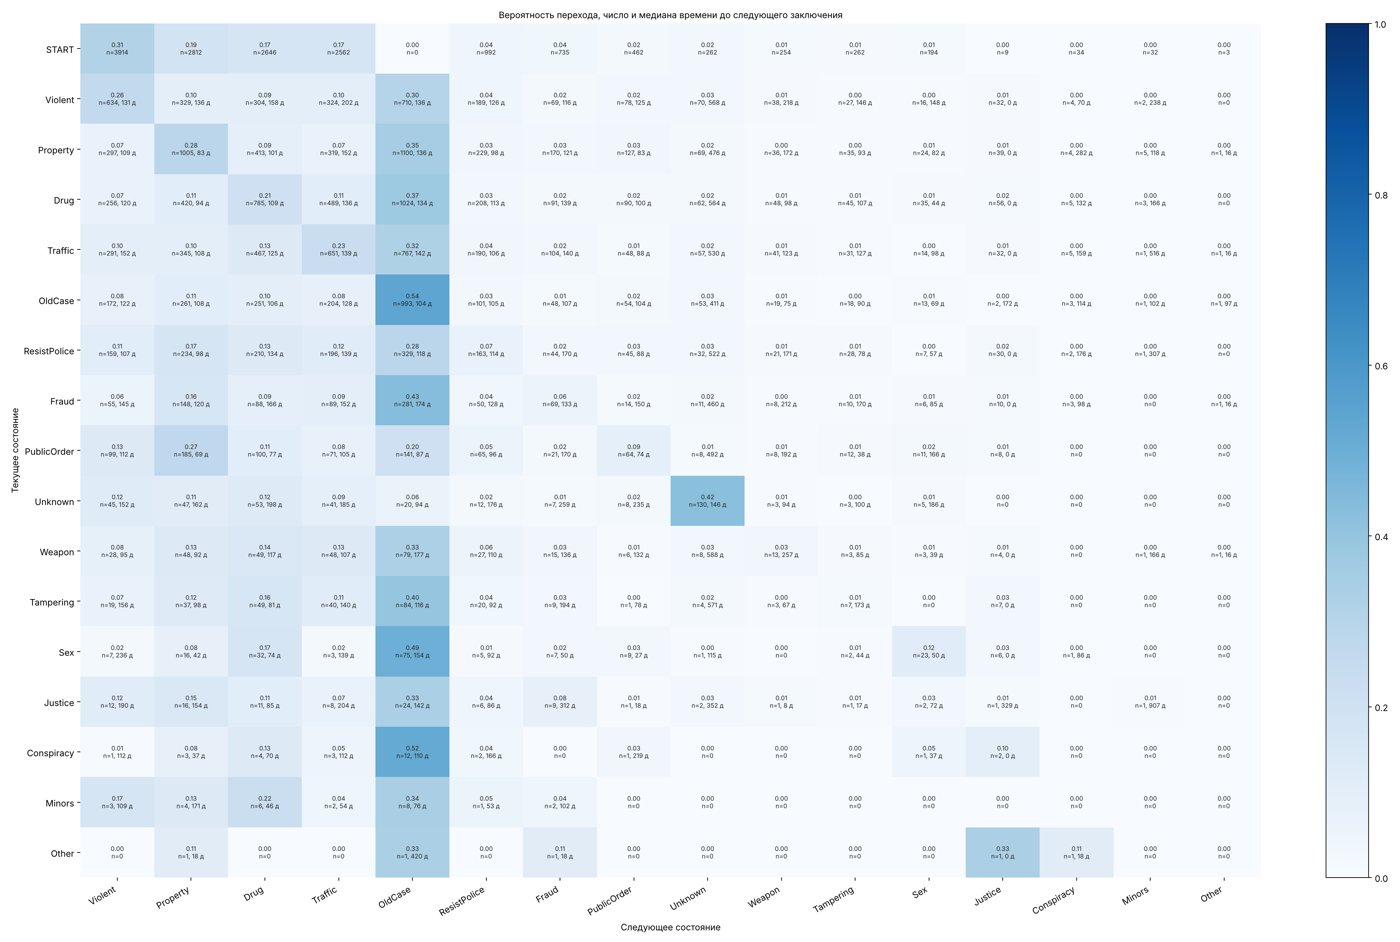

In [15]:
med = arcs.set_index(["from", "to"])["median_days"].to_dict()
base.plot_matrix(probs, raw_pairs.drop(columns="CENSORED"), OUT / "transition_matrix.png", med)
show(OUT / "transition_matrix.png")

**Как читать матрицу.** Строка — текущее состояние, столбец — следующее; в клетке вероятность, число пар `n` и медиана дней до следующего заключения. Диагональ — повтор того же типа (самопереход, петля на графе).

In [16]:
# самопереходы и три самых вероятных перехода из каждого состояния
crime = [s for s in labels if s != OLDCASE]
loops = pd.Series(np.diag(probs.loc[labels, labels]), index=labels)
n_tr = raw_pairs.drop(columns="CENSORED").loc[labels].sum(axis=1)
print(f"средний самопереход по типам преступлений: {loops[crime].mean():.3f}; "
      f"доля самопереходов среди всех переходов (по весу): {np.trace(wcounts.loc[labels, labels].values) / wcounts.loc[labels].values.sum():.3f}")
top3 = (arcs[arcs["from"] != START].sort_values("p", ascending=False).groupby("from").head(3)
        .assign(arc=lambda a: a["to"] + " " + a["p"].map("{:.2f}".format) + " (" + a["median_days"].map("{:.0f}".format) + " д)")
        .groupby("from")["arc"].apply(list).apply(pd.Series))
top3.columns = ["1-й", "2-й", "3-й"][:top3.shape[1]]
top3.insert(0, "самопереход", loops.round(2))
top3.insert(0, "n переходов", n_tr)
top3.sort_values("n переходов", ascending=False)

средний самопереход по типам преступлений: 0.120; доля самопереходов среди всех переходов (по весу): 0.273


,n переходов,самопереход,1-й,2-й,3-й
from,,,,,
Property,3873,0.28,OldCase 0.35 (136 д),Property 0.28 (83 д),Drug 0.09 (101 д)
Drug,3617,0.21,OldCase 0.37 (134 д),Drug 0.21 (109 д),Property 0.11 (94 д)
Traffic,3045,0.23,OldCase 0.32 (142 д),Traffic 0.23 (139 д),Drug 0.13 (125 д)
Violent,2826,0.26,OldCase 0.30 (136 д),Violent 0.26 (131 д),Traffic 0.10 (202 д)
OldCase,2194,0.54,OldCase 0.54 (104 д),Property 0.11 (108 д),Drug 0.10 (106 д)
ResistPolice,1501,0.07,OldCase 0.28 (118 д),Property 0.17 (98 д),Drug 0.13 (134 д)
Fraud,843,0.06,OldCase 0.43 (174 д),Property 0.16 (120 д),Traffic 0.09 (152 д)
PublicOrder,793,0.09,Property 0.27 (69 д),OldCase 0.20 (87 д),Violent 0.13 (112 д)
Unknown,374,0.42,Unknown 0.42 (146 д),Drug 0.12 (198 д),Violent 0.12 (152 д)


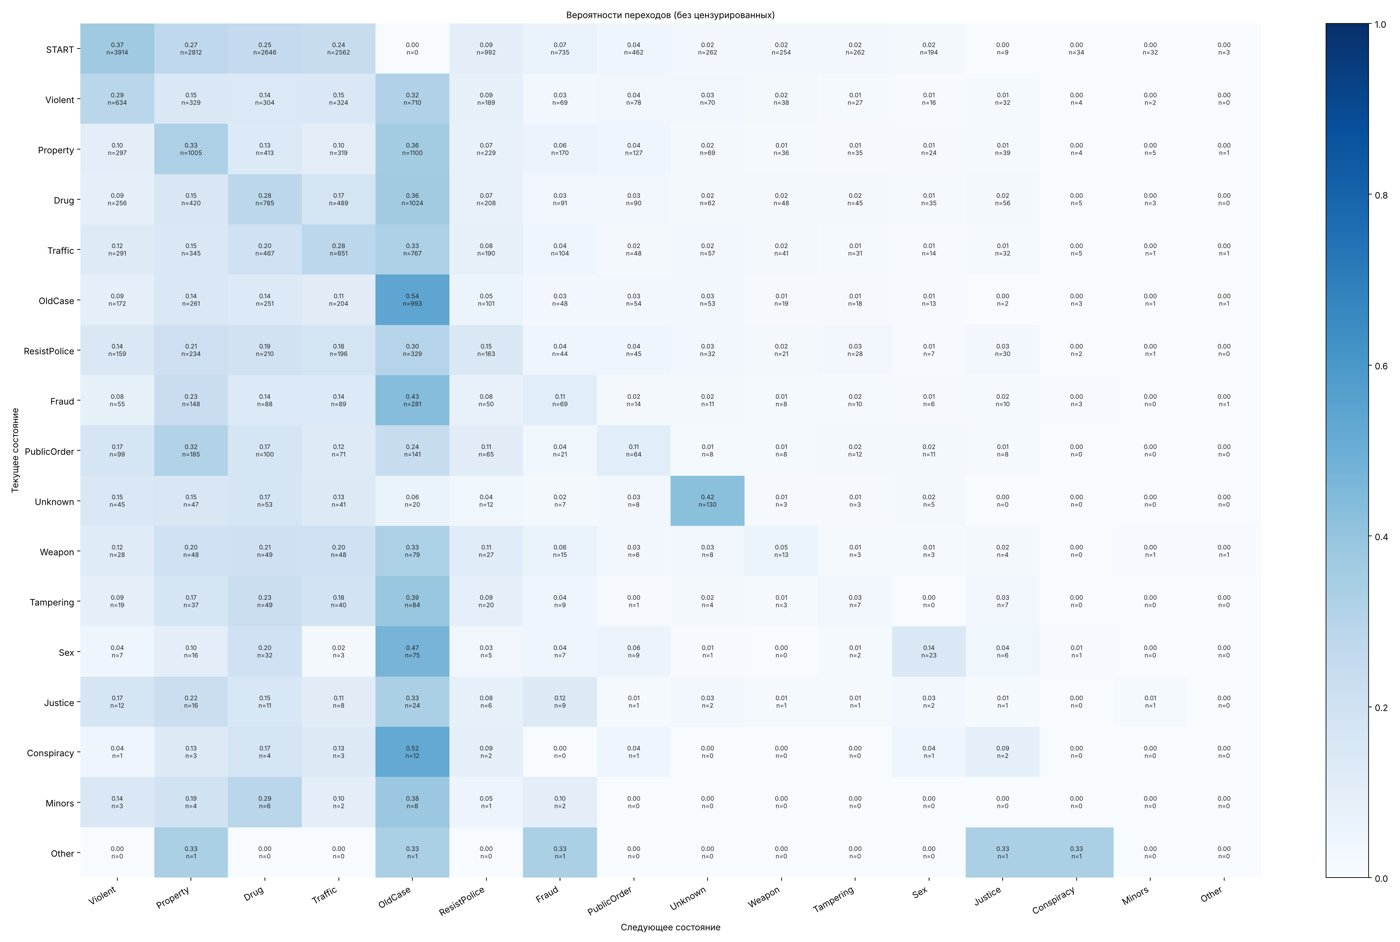

In [17]:
# матрица «следующий эпизод содержит тип» (без весов)
base.plot_matrix(contains.clip(upper=1), raw_pairs.drop(columns="CENSORED"), OUT / "transition_contains.png")
show(OUT / "transition_contains.png")

## Шаг 5. Граф переходов и DFG

### 5.1. Граф переходов
Тот же результат в виде графа: узлы — состояния, дуги с $p \ge$ порога, подпись — вероятность и медиана дней, толщина дуги пропорциональна $p$, самопереходы красные. Рисуется пакетом `graphviz`.

дуг с p >= 0.10: 61 | с p >= 0.05: 90


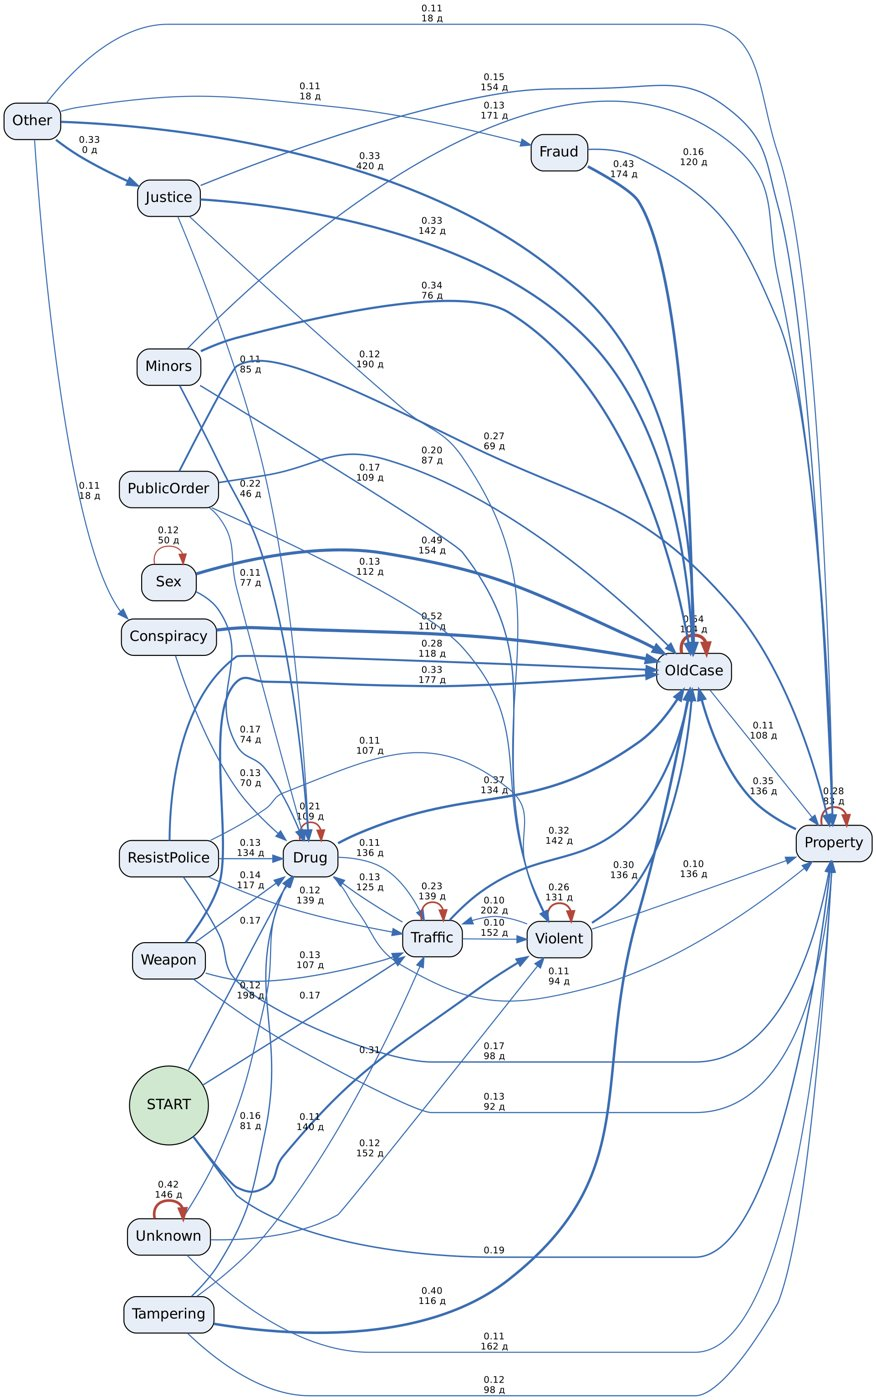

In [18]:
def save_main_graph(arcs, path, min_p=0.05):
    import graphviz
    g = graphviz.Digraph(format="png", graph_attr=dict(rankdir="LR", dpi="160", fontname="Helvetica"),
                         node_attr=dict(shape="box", style="rounded,filled", fillcolor="#e8eef7", fontname="Helvetica"),
                         edge_attr=dict(fontname="Helvetica", fontsize="9"))
    a = arcs[arcs["p"] >= min_p]
    for _, r in a.iterrows():
        lbl = f'{r["p"]:.2f}' + (f'\n{r["median_days"]:.0f} д' if pd.notna(r["median_days"]) else "")
        g.edge(r["from"], r["to"], label=lbl, penwidth=f'{0.5 + 5 * r["p"]:.2f}',
               color="#3b6db3" if r["from"] != r["to"] else "#b3473b")
    g.node(START, shape="circle", fillcolor="#cfe8cf")
    g.render(str(path), cleanup=True)
    return Path(str(path) + ".png")


def graph(min_p, name):
    # нарисовать заново, если есть Graphviz, иначе взять сохранённый рисунок
    if graphviz_ok():
        return save_main_graph(arcs, OUT / name, min_p)
    p = RES / "figures" / f"{name}.png"
    return p if p.exists() else RES / "figures" / "transition_graph_p0.05.png"


print("дуг с p >= 0.10:", int((arcs["p"] >= 0.10).sum()), "| с p >= 0.05:", int((arcs["p"] >= 0.05).sum()))
show(graph(0.10, "transition_graph_p0.10"))

С порогом 0.05 граф подробнее:

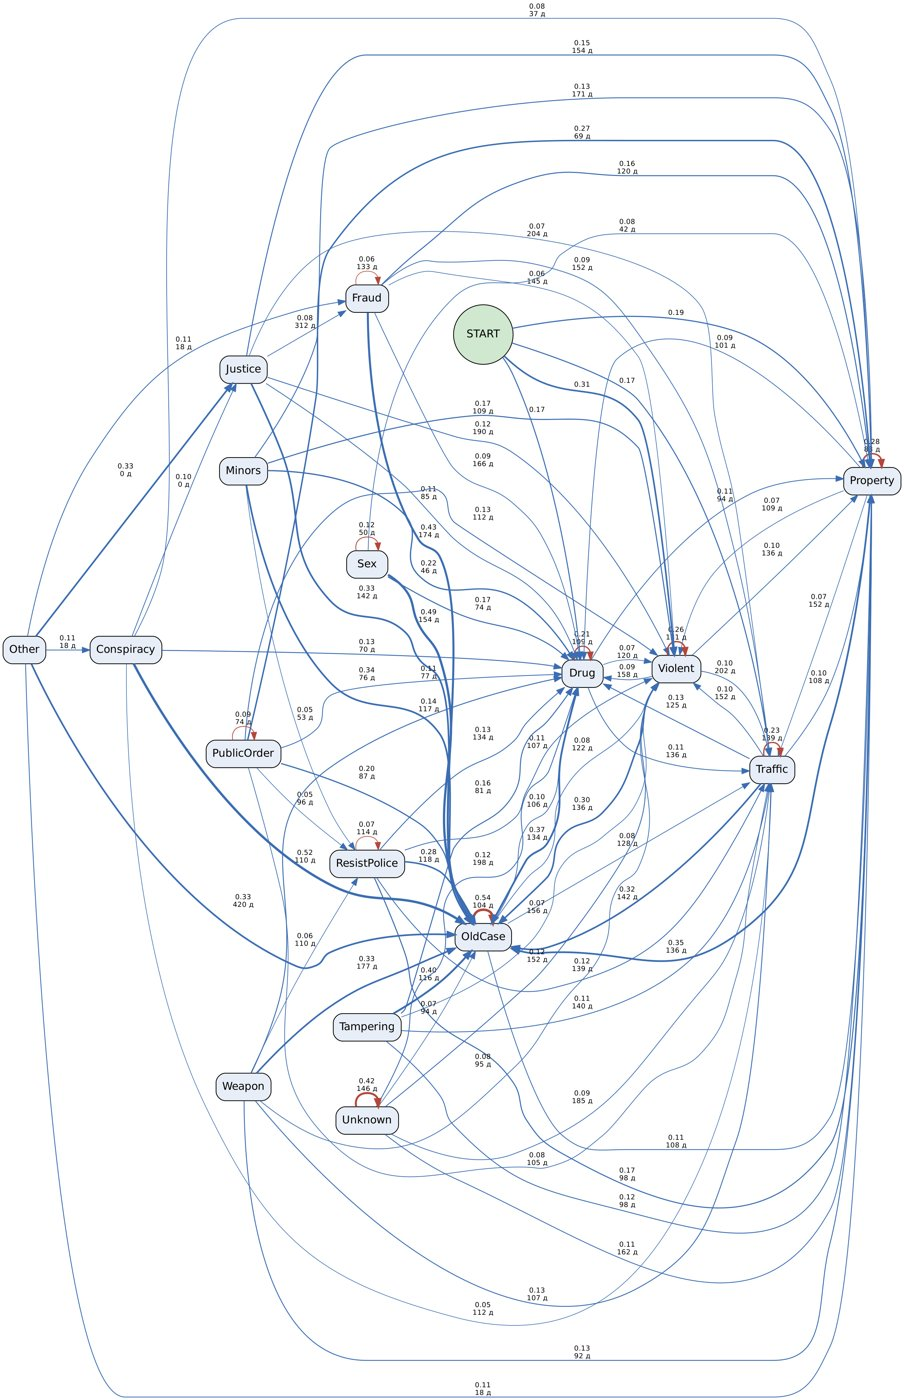

In [19]:
show(graph(0.05, "transition_graph_p0.05"))

In [20]:
# самые частые дуги
arcs.sort_values("n_pairs", ascending=False).head(20)

,from,to,p,p_contains,n_pairs,weight,median_days,q25_days,q75_days
0,START,Violent,0.313,0.370,3914,3311.702,NaN,NaN,NaN
1,START,Property,0.187,0.266,2812,1976.719,NaN,NaN,NaN
2,START,Drug,0.167,0.250,2646,1767.102,NaN,NaN,NaN
3,START,Traffic,0.166,0.242,2562,1759.386,NaN,NaN,NaN
34,Property,OldCase,0.351,0.358,1100,781.833,136.5,60.75,300.25
50,Drug,OldCase,0.372,0.362,1024,718.433,133.5,63.00,255.50
31,Property,Property,0.282,0.327,1005,626.910,83.0,29.00,200.00
81,OldCase,OldCase,0.535,0.535,993,993.000,104.0,50.00,204.00
4,START,ResistPolice,0.042,0.094,992,439.819,NaN,NaN,NaN
48,Drug,Drug,0.211,0.278,785,406.926,109.0,41.00,235.00


### 5.2. DFG PM4Py (directly-follows graph)
Стандартная картинка PM4Py по тем же парам эпизодов: на дугах число пар (frequency) или медиана времени (performance). Входящие стрелки — начало (первый эпизод), исходящие — цензурирование (последний эпизод).

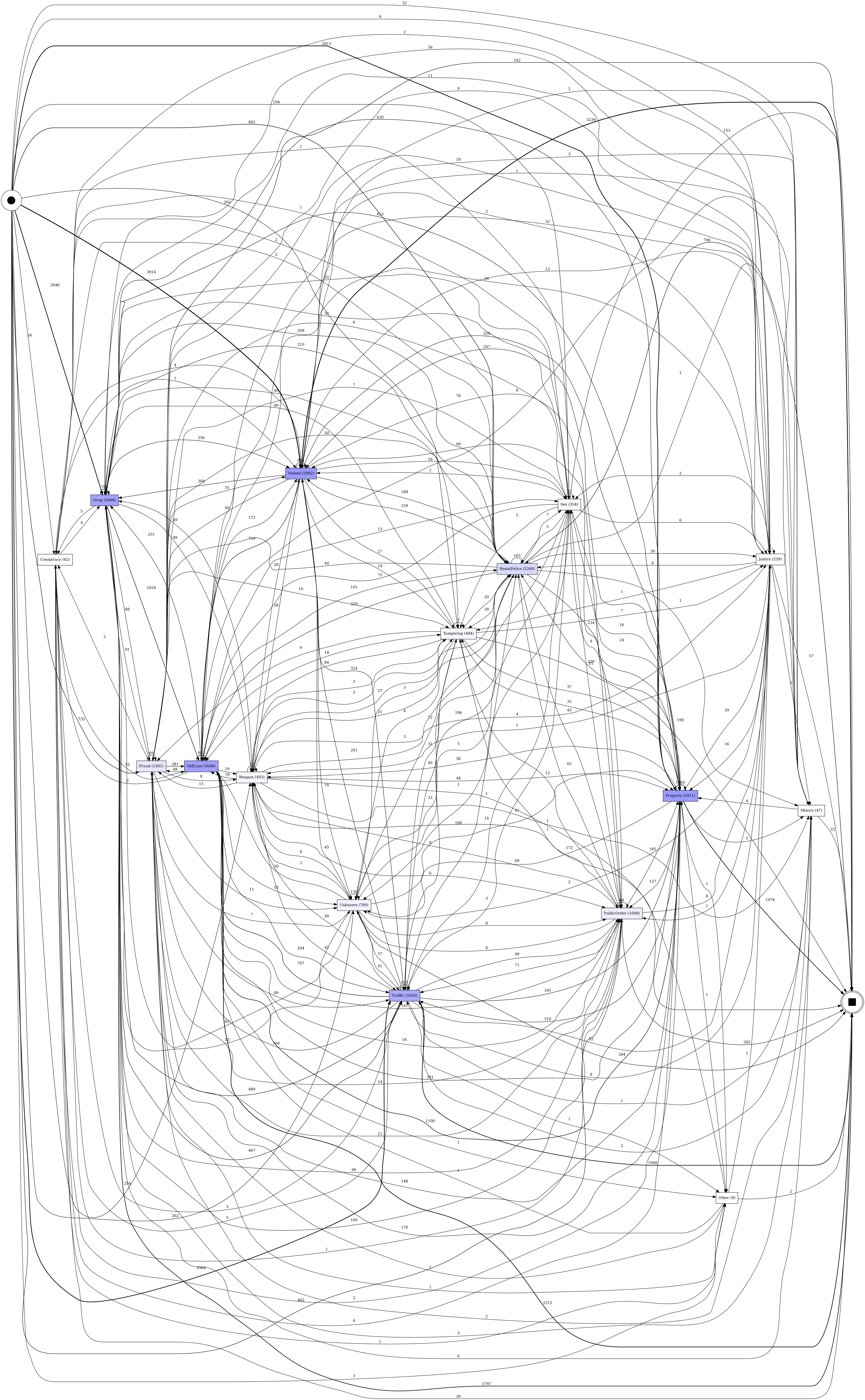

In [21]:
def save_episode_dfg(arcs, df, path, perf_path):
    a = arcs[arcs["from"] != START]
    dfg = {(r["from"], r["to"]): int(r["n_pairs"]) for _, r in a.iterrows()}
    sa = {k: int(v) for k, v in df[df["event_idx"] == 1].explode("types")["types"].value_counts().items()}
    ea = {k: int(v) for k, v in df[df["censored"]].explode("types")["types"].value_counts().items()}
    pm4py.save_vis_dfg(dfg, sa, ea, str(path))
    perf = {(r["from"], r["to"]): float(r["median_days"]) * 86400 for _, r in a.iterrows() if pd.notna(r["median_days"])}
    pm4py.save_vis_performance_dfg(perf, sa, ea, str(perf_path))


FIGS = OUT if graphviz_ok() else RES / "figures"
if graphviz_ok():
    save_episode_dfg(arcs, df, OUT / "dfg_frequency.png", OUT / "dfg_performance.png")
show(FIGS / "dfg_frequency.png", width=1100)

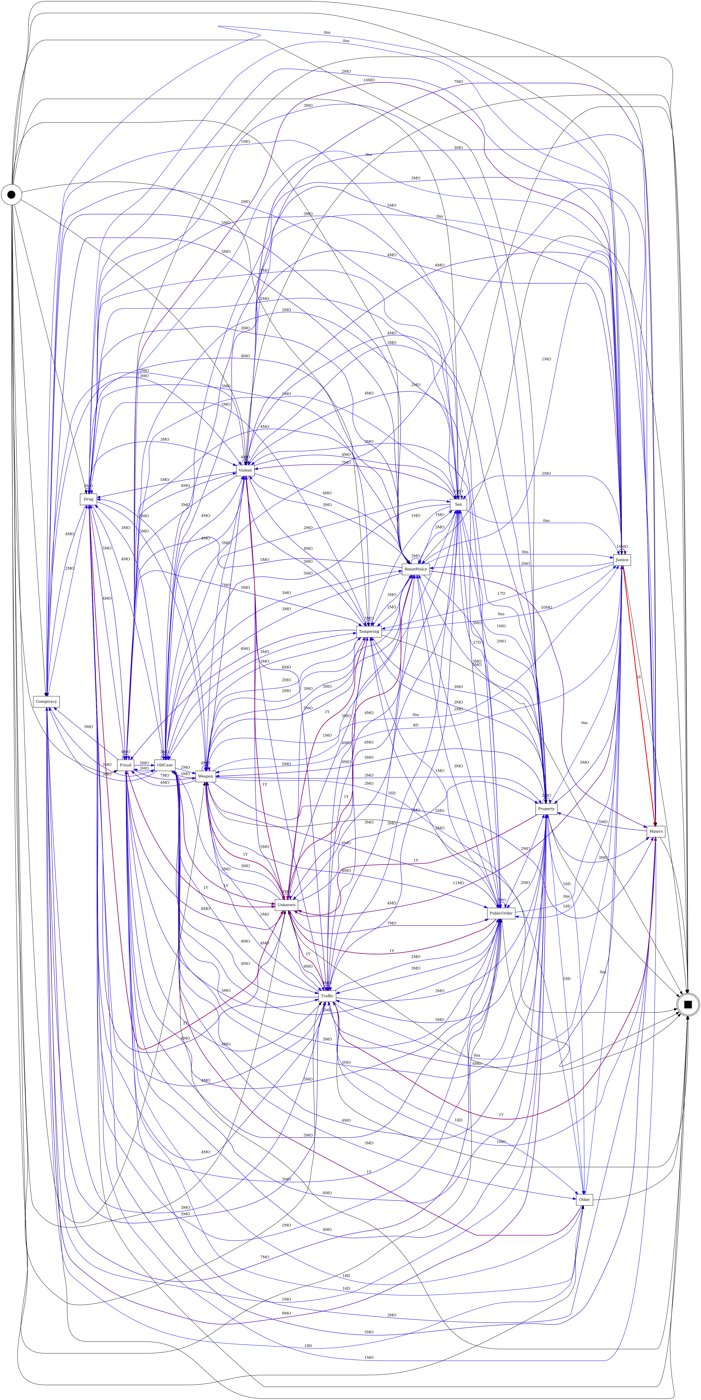

In [22]:
show(FIGS / "dfg_performance.png", width=1100)

## Шаг 6. Развилки (несколько типов в одном эпизоде)

Какие типы встречаются вместе. В матрице совместной встречаемости строка $a$, столбец $b$ — доля эпизодов с $a$, в которых есть и $b$. `share_alone` — доля эпизодов с типом, где он единственный.

In [23]:
def fork_tables(df, labels):
    n = df["n_types"].value_counts().sort_index()
    combos = df.loc[df["n_types"] > 1, "combo"].value_counts()
    combos = pd.DataFrame({"episodes": combos, "share_of_multi": (combos / combos.sum()).round(3)})
    e = df[["ep_row", "types"]].explode("types")
    m = e.merge(e, on="ep_row")
    co = pd.crosstab(m["types_x"], m["types_y"]).reindex(index=labels, columns=labels, fill_value=0)
    co_p = co.div(np.diag(co), axis=0)
    alone = df[df["n_types"] == 1].explode("types")["types"].value_counts()
    tot = e["types"].value_counts()
    solo = pd.DataFrame({"episodes_with_type": tot, "alone": alone.reindex(tot.index, fill_value=0)})
    solo["share_alone"] = (solo["alone"] / solo["episodes_with_type"]).round(3)
    return n, combos, co, co_p, solo


n_types, combos, co, co_p, solo = fork_tables(df, labels)
display(n_types.rename("шагов").to_frame().T)
display(combos.head(12))
solo

n_types,1,2,3,4,5,6,7
шагов,16051,4351,1106,255,46,6,2


,episodes,share_of_multi
combo,,
Drug+Traffic,1041,0.181
Fraud+Property,491,0.085
Property+Violent,350,0.061
Property+ResistPolice,292,0.051
Drug+Property,268,0.046
ResistPolice+Violent,246,0.043
Property+Traffic,185,0.032
ResistPolice+Traffic,136,0.024
Drug+Violent,136,0.024


,episodes_with_type,alone,share_alone
types,,,
Violent,5462,3812,0.698
Property,5048,2550,0.505
Drug,4622,1988,0.430
Traffic,4287,1934,0.451
OldCase,4070,4070,1.000
ResistPolice,1809,153,0.085
Fraud,1193,224,0.188
PublicOrder,868,267,0.308
Unknown,653,653,1.000


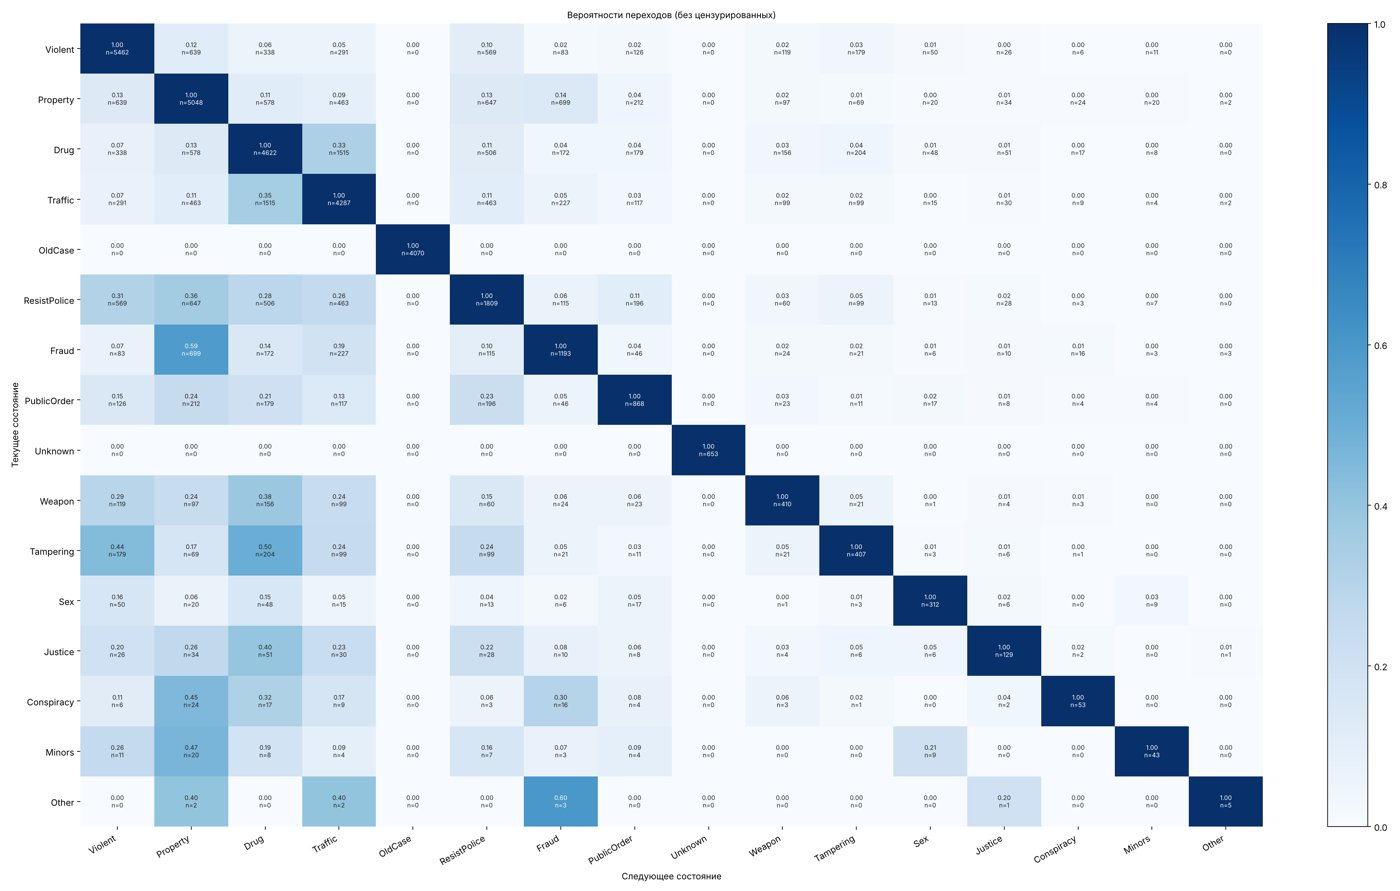

In [24]:
base.plot_matrix(co_p, co, OUT / "fork_cooccurrence.png")
show(OUT / "fork_cooccurrence.png")

## Шаг 7. От чего зависит следующее состояние

Для каждой пары (текущий тип → следующий тип) берутся признаки текущего эпизода: пол, возраст, раса, класс обвинения (Felony / Misdemeanor), длительность заключения, интервал до предыдущего, номер события, число типов, предыдущая комбинация.
- **V Крамера** — сила связи признака со следующим состоянием, отдельно для каждого текущего состояния (0 — нет связи, 1 — полная);
- **дерево решений** (глубина 4) предсказывает следующий тип по всем признакам сразу; важность признака = вклад в разбиения.

In [25]:
from sklearn.tree import DecisionTreeClassifier, export_text


def transition_drivers(df, labels):
    d, _ = pair_rows(df)
    feats = ["sex", "age_group", "race", "charge_class", "dur_class", "gap_prev_bin", "event_idx_bin",
             "n_types_bin", "prev_combo"]
    d["gap_prev_bin"] = pd.cut(d["gap_prev"].fillna(-1), [-np.inf, -0.5, 30, 180, 365, np.inf],
                               labels=["first", "<=30d", "31-180d", "181-365d", ">365d"]).astype(str)
    d["event_idx_bin"] = d["event_idx"].clip(upper=4).astype(str).replace("4", "4+")
    d["n_types_bin"] = d["n_types"].clip(upper=3).astype(str).replace("3", "3+")
    rows = []
    for src in labels:
        sub = d[d["src"] == src]
        for f in feats:
            ct = pd.crosstab(sub[f], sub["dst"], values=sub["w"], aggfunc="sum").fillna(0)
            ct = ct.loc[ct.sum(axis=1) >= 20]
            ct = ct.loc[:, ct.sum(axis=0) > 0]
            if ct.shape[0] < 2 or ct.shape[1] < 2:
                continue
            v, p = base.cramers_v(ct)
            rows.append(dict(from_state=src, feature=f, n=round(ct.values.sum(), 1), cramers_v=round(v, 3), p_value=p))
    assoc = pd.DataFrame(rows).sort_values(["from_state", "cramers_v"], ascending=[True, False])
    prof = []
    for f in feats:
        g = pd.crosstab(d[f], d["dst"], values=d["w"], aggfunc="sum", normalize="index").fillna(0)
        g = g.reindex(columns=labels, fill_value=0)
        g.insert(0, "n", d.groupby(f)["w"].sum().round(1))
        g.index = [f"{f}={i}" for i in g.index]
        prof.append(g.round(3))
    profile = pd.concat(prof)
    X = pd.get_dummies(d[["src"] + feats].astype(str), drop_first=False)
    tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, random_state=SEED,
                                  class_weight="balanced").fit(X, d["dst"], sample_weight=d["w"])
    imp = pd.Series(tree.feature_importances_, index=X.columns)
    imp = imp.groupby(lambda c: next(f for f in ["src"] + feats if c.startswith(f + "_"))).sum()
    return assoc, profile, imp.sort_values(ascending=False).round(3), export_text(tree, feature_names=list(X.columns))


assoc, profile, imp, tree_txt = transition_drivers(df, labels)
assoc.to_csv(OUT / "drivers_cramers_v.csv", index=False)
saved_imp = pd.read_csv(RES / "tables" / "drivers_tree_importance.csv", index_col=0)["importance"]
pd.DataFrame({"важность": imp, "сохранено": saved_imp})

,важность,сохранено
src,0.657,0.657
sex,0.123,0.123
dur_class,0.107,0.107
charge_class,0.085,0.085
event_idx_bin,0.028,0.028
age_group,0.000,0.000
n_types_bin,0.000,0.000
gap_prev_bin,0.000,0.000
race,0.000,0.000
prev_combo,0.000,0.000


In [26]:
# самые сильные связи (V Крамера >= 0.15 при n >= 100)
assoc[(assoc["n"] >= 100) & (assoc["cramers_v"] >= 0.15)].sort_values("cramers_v", ascending=False).head(15)

,from_state,feature,n,cramers_v,p_value
91,Sex,charge_class,121.2,0.482,5.169032e-03
77,Unknown,prev_combo,242.0,0.431,4.982095e-06
88,Sex,sex,121.2,0.353,2.366898e-01
90,Sex,race,109.7,0.352,3.292936e-01
94,Sex,event_idx_bin,115.4,0.321,4.786177e-01
80,Weapon,dur_class,113.3,0.311,7.851253e-01
92,Sex,dur_class,113.0,0.291,6.396770e-01
76,Unknown,event_idx_bin,309.0,0.290,1.799882e-05
75,Unknown,gap_prev_bin,299.0,0.282,1.276702e-04
95,Sex,n_types_bin,114.5,0.282,6.962752e-01


In [27]:
print(tree_txt[:3000])

|--- src_Unknown <= 0.50
|   |--- src_Sex <= 0.50
|   |   |--- sex_Male <= 0.50
|   |   |   |--- dur_class_S1_<=1d <= 0.50
|   |   |   |   |--- class: Sex
|   |   |   |--- dur_class_S1_<=1d >  0.50
|   |   |   |   |--- class: Minors
|   |   |--- sex_Male >  0.50
|   |   |   |--- charge_class_Misdemeanor <= 0.50
|   |   |   |   |--- class: OldCase
|   |   |   |--- charge_class_Misdemeanor >  0.50
|   |   |   |   |--- class: Violent
|   |--- src_Sex >  0.50
|   |   |--- class: Sex
|--- src_Unknown >  0.50
|   |--- event_idx_bin_1 <= 0.50
|   |   |--- class: Unknown
|   |--- event_idx_bin_1 >  0.50
|   |   |--- class: Unknown



## Шаг 8. Модели процесса: Inductive Miner, Heuristics Miner, DFG

Модели учатся на журнале 80% людей (`train`), проверяются на 20% (`test`), разбиение по людям (`GroupShuffleSplit`, seed 42).
- **Inductive Miner (IM)**, порог шума 0 / 0.2 / 0.5 — всегда даёт корректную (sound) сеть Петри, но с развилками превращается в «параллельный блок независимых циклов»;
- **Heuristics Miner (HM)**, порог зависимости 0.5 / 0.9 — связи по частоте directly-follows;
- **DFG с фильтром** — дуги с долей ≥ 5 / 10 / 20% от исходящих из узла, переведённые в сеть Петри.

Метрики качества: **fitness** (насколько журнал теста воспроизводится моделью: token replay и alignments), **precision** ETC (насколько модель не разрешает лишнего), `lost_occ_share` — доля переходов теста, которых модель не допускает, `extra_edges` — лишние допускаемые переходы.

In [28]:
from sklearn.model_selection import GroupShuffleSplit

cases = log["case:concept:name"].unique()
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(cases, groups=cases))
train_log = log[log["case:concept:name"].isin(set(cases[tr_idx]))]
test_log = log[log["case:concept:name"].isin(set(cases[te_idx]))]
print(f"train: {train_log['case:concept:name'].nunique():,} людей, test: {test_log['case:concept:name'].nunique():,} людей")

models = {}
if RUN_MODELS:
    t0 = time.time()
    for nt in [0.0, 0.2, 0.5]:
        models[f"IM_noise{nt}"] = pm4py.discover_petri_net_inductive(train_log, noise_threshold=nt)
    for dep in [0.5, 0.9]:
        models[f"HM_dep{dep}"] = pm4py.discover_petri_net_heuristics(train_log, dependency_threshold=dep)
    dfg_tr, sa_tr, ea_tr = pm4py.discover_dfg(train_log)
    out_tot = pd.Series(dfg_tr).groupby(level=0).sum()
    sa_tot = sum(sa_tr.values())
    for thr in [0.05, 0.10, 0.20]:
        dfg_f = {k: v for k, v in dfg_tr.items() if v / out_tot[k[0]] >= thr}
        sa_f = {k: v for k, v in sa_tr.items() if v / sa_tot >= thr}
        models[f"DFG_p>={thr}"] = pm4py.convert_to_petri_net(dfg_f, sa_f, ea_tr)
    print(f"моделей: {len(models)}, {time.time() - t0:.0f} с")
    display(pd.DataFrame({k: dict(places=len(n.places), transitions=len(n.transitions),
                                  silent=sum(t.label is None for t in n.transitions)) for k, (n, i, f) in models.items()}).T)

train: 8,464 людей, test: 2,116 людей


моделей: 8, 1 с


,places,transitions,silent
IM_noise0.0,71,92,76
IM_noise0.2,53,77,61
IM_noise0.5,44,65,49
HM_dep0.5,42,172,156
HM_dep0.9,32,162,147
DFG_p>=0.05,18,110,15
DFG_p>=0.1,18,80,15
DFG_p>=0.2,18,38,15


### 8.1. Качество моделей на тесте

Пересчёт всех моделей занимает часы (выравнивания для IM с 15 состояниями не считались вообще), поэтому таблица берётся из сохранённого `model_quality.csv`. Флаг `RUN_EVAL = True` пересчитает метрики для HM dep 0.9 и покажет их рядом.

In [29]:
quality = pd.read_csv(RES / "tables" / "model_quality.csv")
cols = [c for c in ["model", "fitness_tbr", "fitness_align", "precision_etc", "f1", "lost_edges", "lost_occ_share",
                    "extra_edges", "places", "transitions", "silent"] if c in quality.columns]
quality[quality["split"] == "test"][cols].reset_index(drop=True)

,model,fitness_tbr,fitness_align,precision_etc,f1,lost_edges,lost_occ_share,extra_edges,places,transitions,silent
0,IM_noise0.0,1.0000,NaN,0.5355,0.6975,1,0.0002,94,71,92,76
1,IM_noise0.2,0.9753,NaN,0.7629,0.8561,63,0.1143,28,53,77,61
2,IM_noise0.5,0.9140,NaN,0.7623,0.8313,81,0.1924,15,44,65,49
3,HM_dep0.5,0.9347,0.8686,0.6901,0.7940,0,0.0000,96,42,172,156
4,HM_dep0.9,0.9946,0.9891,0.6746,0.8039,48,0.0156,5,32,162,147
5,DFG_p>=0.05,0.9457,0.8923,0.8093,0.8722,122,0.1715,0,18,110,15
6,DFG_p>=0.1,0.9177,0.8301,0.8883,0.9027,142,0.2724,0,18,80,15
7,DFG_p>=0.2,0.6830,0.2376,0.9923,0.8091,174,0.8841,0,18,38,15


In [30]:
if RUN_EVAL and RUN_MODELS:
    t0 = time.time()
    q, edges = base.evaluate({"HM_dep0.9": models["HM_dep0.9"]}, train_log, test_log, max_states=300_000)
    print(f"{time.time() - t0:.0f} с")
    display(q[q["split"] == "test"][cols])
else:
    print("RUN_EVAL = False: пересчёт пропущен")

RUN_EVAL = False: пересчёт пропущен


### 8.2. Heuristics Miner (dep 0.9): сеть Петри и heuristics net

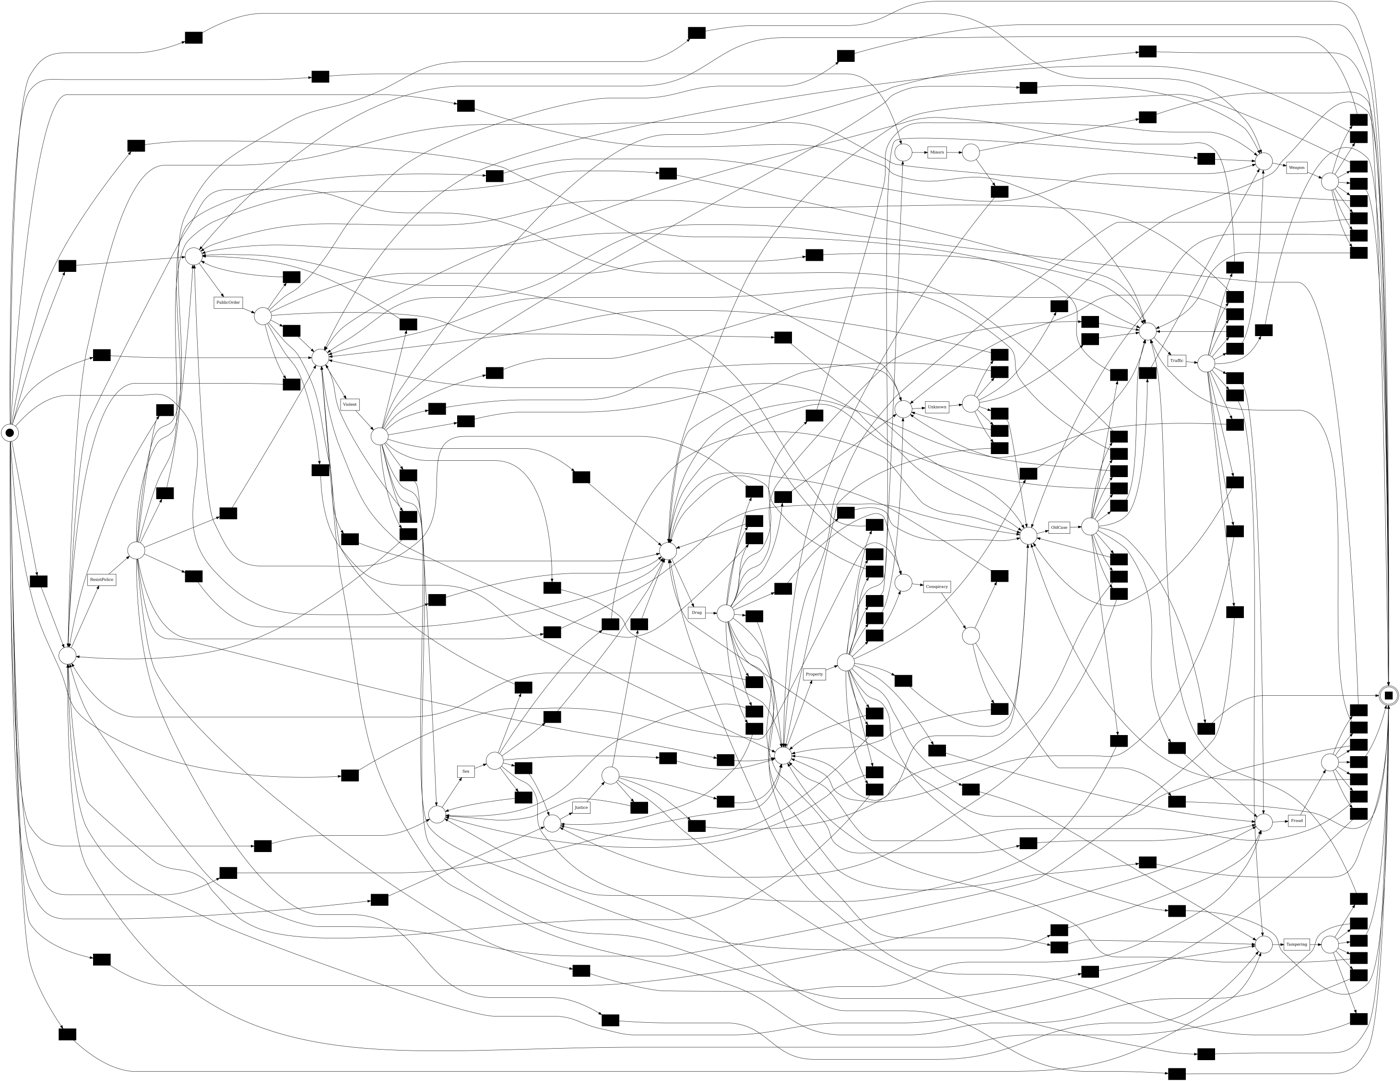

In [31]:
def petri_png(name):
    path = OUT / f"petri_{name}.png"
    if RUN_MODELS and graphviz_ok():
        pm4py.save_vis_petri_net(*models[name], str(path))
        return path
    return RES / "figures" / f"petri_{name}.png"


show(petri_png("HM_dep0.9"), width=1200)

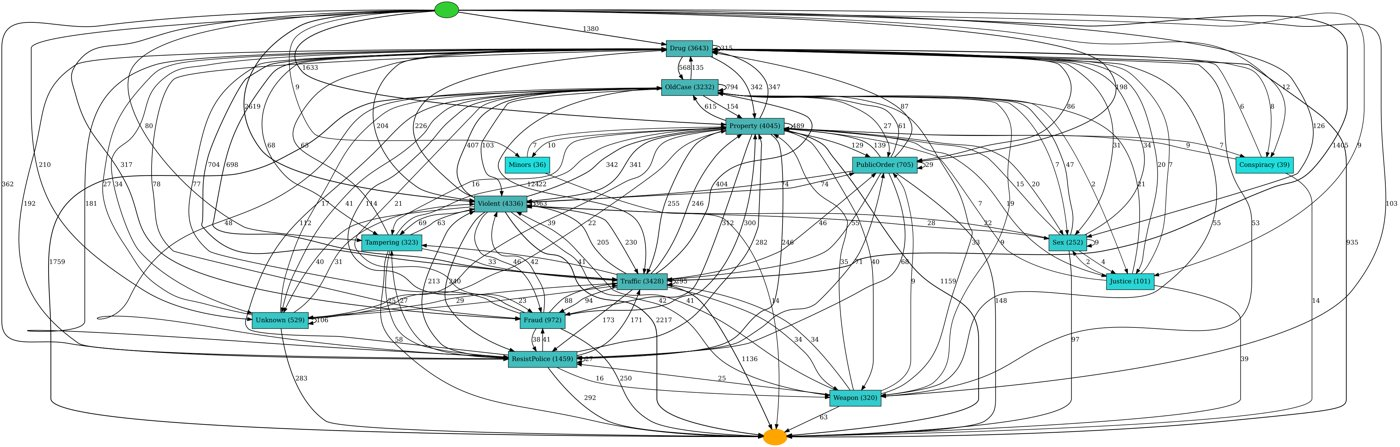

In [32]:
# на дугах heuristics net — число directly-follows и зависимость
if RUN_MODELS and graphviz_ok():
    pm4py.save_vis_heuristics_net(pm4py.discover_heuristics_net(train_log, dependency_threshold=0.9),
                                  str(OUT / "heuristics_net_dep0.9.png"))
    show(OUT / "heuristics_net_dep0.9.png", width=1200)
else:
    show(RES / "figures" / "heuristics_net_dep0.9.png", width=1200)

### 8.3. Inductive Miner (noise 0.2): дерево процесса и сеть Петри

Дерево показывает, почему IM здесь мало информативен: состояния собираются в параллельный блок (`+`) независимых циклов (`*`), то есть модель почти не различает, из какого типа в какой переходят.

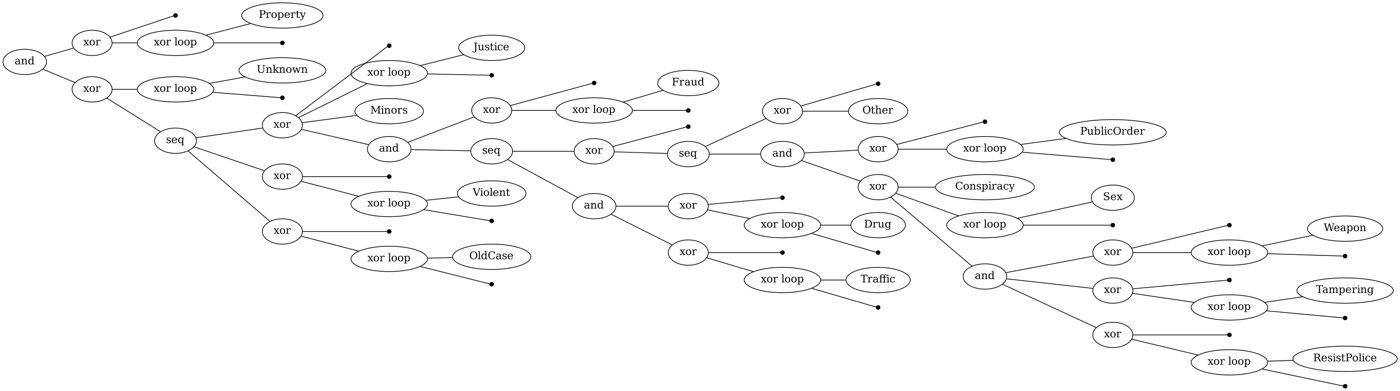

In [33]:
if RUN_MODELS and graphviz_ok():
    pm4py.save_vis_process_tree(pm4py.discover_process_tree_inductive(train_log, noise_threshold=0.2),
                                str(OUT / "process_tree_IM_noise0.2.png"))
    show(OUT / "process_tree_IM_noise0.2.png", width=1100)
else:
    show(RES / "figures" / "process_tree_IM_noise0.2.png", width=1100)

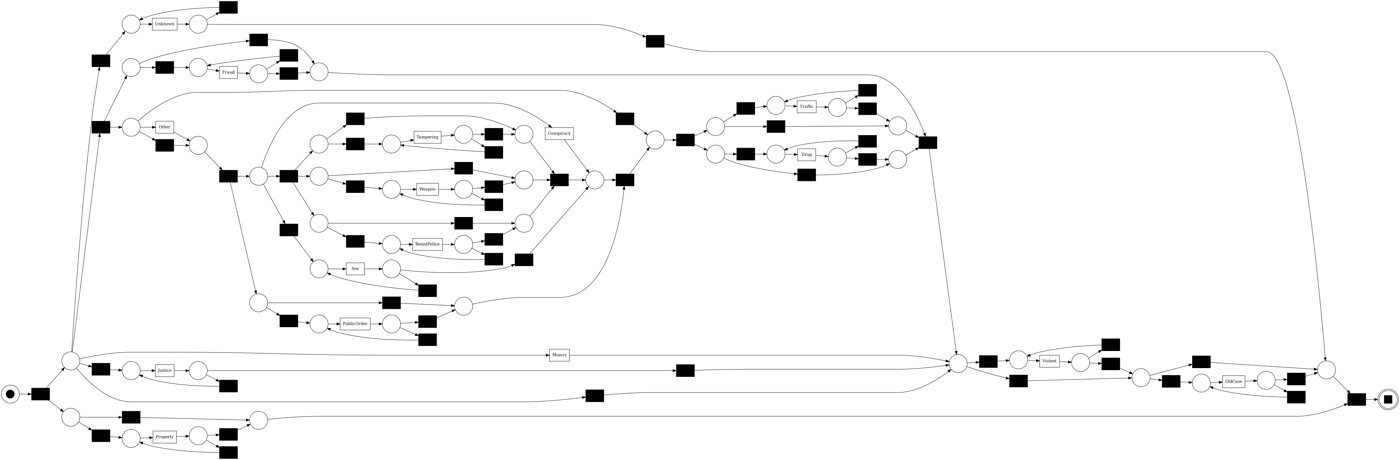

In [34]:
show(petri_png("IM_noise0.2"), width=1200)

## Шаг 9. Сравнение с другими вариантами

Берутся сохранённые результаты соседних папок `stage1/…` (если они есть рядом): число эпизодов и переходов, доля развилок, средний самопереход по типам преступлений (без `OldCase`) и качество HM dep 0.9 на тесте.

In [35]:
OTHERS = {"все новые": "all_new/results", "OldCase": "oldcase/results",
          "без OldCase": "no_oldcase/results", "склейка, все новые": "glue7/results_glue_all",
          "склейка, без OldCase": "glue7/results_glue_noold"}
rows = {}
for name, rel in OTHERS.items():
    r = HERE / ".." / rel
    if not (r / "tables" / "log_info.csv").exists():
        continue
    li = pd.read_csv(r / "tables" / "log_info.csv", index_col=0)["value"]
    pr = pd.read_csv(r / "tables" / "transition_probs.csv", index_col=0)
    tps = [c for c in pr.columns if c != OLDCASE and c in pr.index]
    mq = pd.read_csv(r / "tables" / "model_quality.csv")
    hm = mq[(mq["model"] == "HM_dep0.9") & (mq["split"] == "test")].iloc[0]
    rows[name] = {"эпизодов": int(li["episodes"]), "шагов": int(li["steps"]),
                  "переходов": int(li["transitions_observed"]), "людей с повторами": int(li["people_repeat"]),
                  "доля развилок": float(li["share_multi_type"]),
                  "средний самопереход": round(float(np.mean([pr.loc[s, s] for s in tps])), 3),
                  "HM 0.9 fitness": round(float(hm["fitness_tbr"]), 3), "HM 0.9 precision": round(float(hm["precision_etc"]), 3)}
cmp = pd.DataFrame.from_dict(rows, orient="index")
cmp

,эпизодов,шагов,переходов,людей с повторами,доля развилок,средний самопереход,HM 0.9 fitness,HM 0.9 precision
все новые,21716,21866,11286,5230,0.376,0.328,0.998,0.572
OldCase,21716,21817,11237,5230,0.264,0.120,0.995,0.675
без OldCase,17646,17747,7167,4053,0.325,0.167,0.995,0.698


**Как читать.** «Все новые» и OldCase имеют одинаковое число эпизодов; OldCase переносит повторы старых дел из самопереходов в отдельное состояние. «Без OldCase» убирает эти эпизоды совсем: переходов меньше, самопереходов примерно вдвое меньше, precision HM выше. Склейка ±7 дней почти ничего не меняет (склеивается около 1% эпизодов): возвраты по старому делу не быстрые, поэтому временное окно не заменяет правило по `case_number`.

## Шаг 10. Итог и файлы

Сверка с сохранёнными результатами (шаги 2–4) и список того, что ноутбук записал в `notebook_out/`.

In [36]:
print("log_info совпадает:          ", bool(chk["совпадает"].all()))
print("журнал событий совпадает:    ", bool(same))
print("transition_probs |разница|:  ", float(diff))
sorted(p.name for p in OUT.iterdir())

log_info совпадает:           True
журнал событий совпадает:     True
transition_probs |разница|:   0.0


['drivers_cramers_v.csv',
 'event_log.csv',
 'event_table.csv',
 'fork_cooccurrence.png',
 'log_info.csv',
 'transition_arcs.csv',
 'transition_contains.csv',
 'transition_contains.png',
 'transition_matrix.png',
 'transition_pair_counts.csv',
 'transition_probs.csv']

# Этапы 2–3 (п. 1.1 плана): параметры переходов и модели выживаемости

Кейс: 15 категорий + OldCase. Журнал и граф этапа 1 построены выше; здесь к ним добавляются

- **Этап 2.** Параметры переходов: вероятности $p_{ij}$ и распределения времени между заключениями.
- **Этап 3.** Признаки объекта (возраст, пол, раса, исходный балл COMPAS) и признаки события (тяжесть,
  число обвинений, длительность заключения, номер заключения, старое дело) и модели выживаемости между
  состояниями: CoxPH, дерево и случайный лес выживаемости; влияние признаков на переходы.

**Одна строка = одно заключение человека** (таблица `E`). Из каждого заключения $A$ человек выходит на свободу
и либо попадает в следующее заключение $B$ (переход $A \to B$), либо наблюдение кончается (цензура).

- **Время перехода** $T$ — время на свободе: от выхода из $A$ до входа в $B$, дни (пересечения заключений
  в данных → 0). Это время риска для конкурирующих рисков.
- **Тип следующего события** $K$ — состояние $B$. Пара $(T, K)$ — то, что моделируется в п. 1.2 плана.
- **Цензура.** Последнее заключение человека цензурировано: $T$ — от выхода до конца наблюдения
  (`obs_end`), терминального состояния END нет. Кто на конец наблюдения ещё в заключении, времени на свободе
  не имеет и в моделях выживаемости не участвует (`at_risk = False`), но учтён в долях цензуры.

В журнале этапа 1 заключение с несколькими категориями — развилка из нескольких событий. Для переходов между заключениями нужно одно состояние, поэтому здесь берётся **главная категория** заключения: самая тяжёлая по обвинению (F1 > F2 > F3 > прочие F > M1 > M2 > MO3), `Justice` — только если других нет, при равной тяжести случайная (seed 42); это то же правило, что в эксперименте 1 варианта «категории × 2». Матрица шага 4 выше считает развилки с весами, поэтому вероятности немного отличаются.

Общий код этапов 2–3 — `stage23.py` (тот же файл во всех кейсах). Результаты — в `notebook_out\stage23\`:
CSV-таблицы, `stage23_tables.xlsx` (все таблицы листами) и рисунки в `figures\`.

In [37]:
import stage23 as ST

DB = HERE / ".." / ".." / "stage0 - data" / "compas.db"
OUT23 = OUT / "stage23"
FIG23 = OUT23 / "figures"
FIG23.mkdir(parents=True, exist_ok=True)
RUN_RSF = True              # случайный лес выживаемости (около минуты)
MIN_ARC_EVENTS = 50         # модели Кокса по дугам — только для дуг с таким числом переходов

# обвинения с номером эпизода и тяжестью — для выбора главной категории заключения
ch23, ep23 = load()
ep23 = merge_continuations(ep23)
ch23 = ch23.merge(ep23[["ep_raw", "ep_row"]], on="ep_raw")
people = ST.compas_people(DB)                       # возраст, пол, раса, балл COMPAS из compas.db
E = ST.episodes_variant(df, ch23, people, info["obs_end"])
E.drop(columns=["person_id"]).to_csv(OUT23 / "episodes.csv", index=False)
ST.episodes_summary(E)

людей                               10580.0
заключений                          21716.0
состояний                              15.0
переходов (наблюдались)             11136.0
цензурировано (последние)           10580.0
  из них ещё в заключении             635.0
доля петель X→X                         0.3
медиана дней на свободе до след.      124.0
переходов за 0 дней                   107.0
нет балла COMPAS                       15.0
dtype: float64

**Как читать.** `переходов (наблюдались)` — пары соседних заключений; `цензурировано` — по одному последнему
заключению на человека; `переходов за 0 дней` — следующее заключение началось в день выхода или раньше
(пересечения в данных). `нет балла COMPAS` — у этих людей нет `decile_score`, в моделях этапа 3 они выпадают.

## Этап 2. Параметры переходов

### 2.1. Вероятности переходов

Вложенная цепь Маркова: $p_{ij} = n_{ij} / \sum_k n_{ik}$ — доля переходов в $j$ среди всех **наблюдавшихся**
переходов из $i$. Доля цензуры — доля заключений $i$, после которых следующего заключения не было до конца
наблюдения. $p_{ij}$ не учитывает, когда случился переход и сколько людей не дожило до него под наблюдением;
это делают кумулятивные функции инцидентности в 2.5.

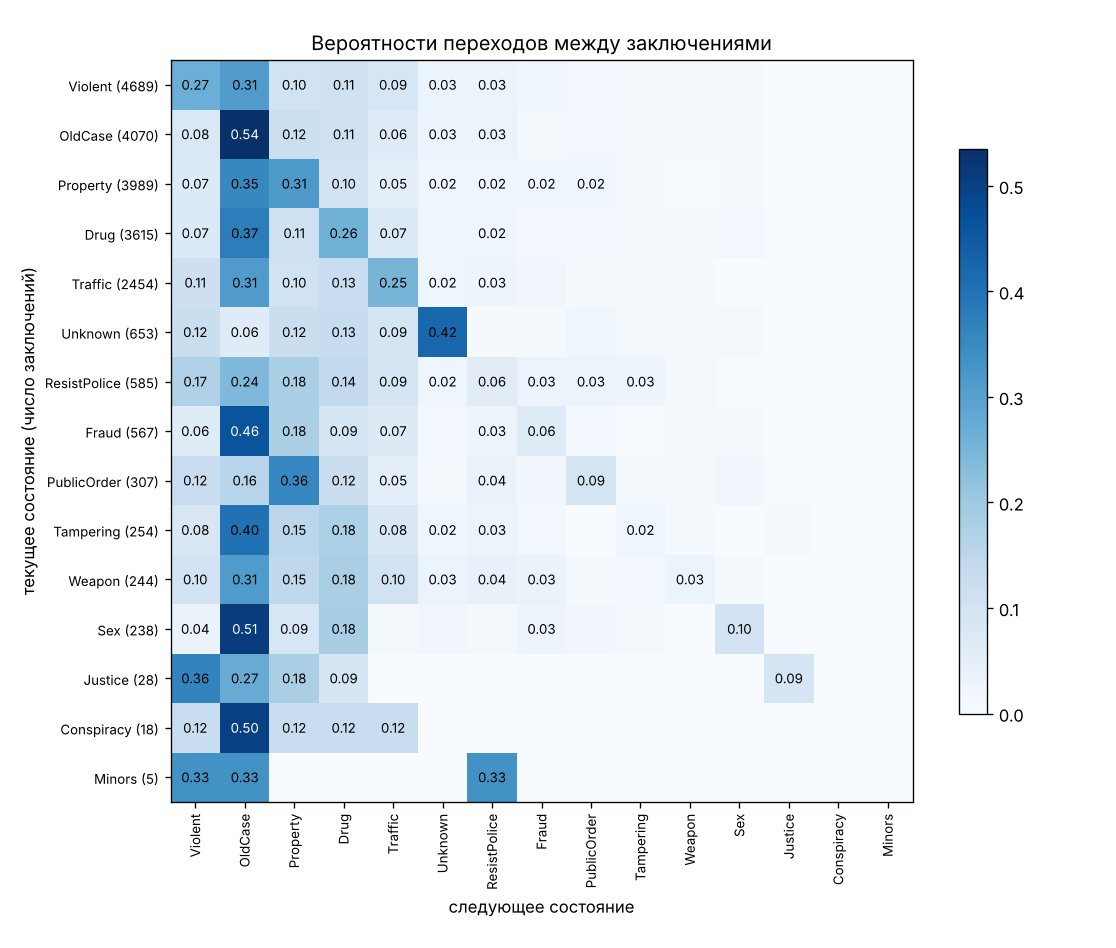

,заключений,переходов,доля цензуры,петля p(i→i)
Violent,4689,1811,0.614,0.266
OldCase,4070,1855,0.544,0.535
Property,3989,2423,0.393,0.314
Drug,3615,2216,0.387,0.260
Traffic,2454,1245,0.493,0.251
Unknown,653,309,0.527,0.421
ResistPolice,585,353,0.397,0.059
Fraud,567,297,0.476,0.064
PublicOrder,307,222,0.277,0.095
Tampering,254,125,0.508,0.024


In [38]:
cnt, P, trans_summary = ST.transition_matrix(E)
cnt.to_csv(OUT23 / "transition_counts.csv")
P.round(4).to_csv(OUT23 / "transition_probs.csv")
trans_summary.to_csv(OUT23 / "transition_summary.csv")
ST.plot_matrix(P, FIG23 / "transition_matrix.png", "Вероятности переходов между заключениями",
               n=trans_summary["заключений"], annotate_min=0.02)
show(FIG23 / "transition_matrix.png")
trans_summary

**Как читать матрицу.** Строка — состояние текущего заключения (в скобках — число заключений), столбец —
следующего; в клетке $p_{ij}$ (подписаны $\ge 0.02$). Диагональ — повтор того же состояния (петля графа).
В таблице: сколько заключений в состоянии, сколько из них закончились переходом, доля цензуры и петля $p_{ii}$.

### 2.2. Время на свободе по дугам

Для каждой дуги $i \to j$ — описательная статистика времени на свободе среди тех, кто совершил этот переход
(дни): число переходов, $p_{ij}$, среднее, квартили, 90-й перцентиль. Показаны дуги с не менее 30 переходами.

In [39]:
arcs23 = ST.arc_times(E)
arcs23.to_csv(OUT23 / "arc_times.csv", index=False)
arcs23[arcs23["n"] >= 30].sort_values("n", ascending=False).head(25)

,from,to,n,p,mean,q25,median,q75,q90
42,OldCase,OldCase,993,0.535,148.4,50.0,104.0,204.0,340.8
56,Property,OldCase,860,0.355,205.8,60.0,138.0,301.2,480.1
9,Drug,OldCase,830,0.375,187.4,62.0,128.0,253.8,434.1
57,Property,Property,762,0.314,142.2,28.0,80.0,202.2,362.5
6,Drug,Drug,576,0.260,167.6,40.0,111.5,229.5,422.5
143,Violent,OldCase,563,0.311,200.8,56.0,133.0,293.0,484.2
151,Violent,Violent,482,0.266,205.0,55.0,133.0,291.2,507.9
117,Traffic,OldCase,386,0.310,194.7,62.0,140.0,275.0,460.5
123,Traffic,Traffic,313,0.251,201.9,59.0,138.0,291.0,497.6
10,Drug,Property,247,0.111,151.4,34.5,94.0,201.5,382.8


### 2.3. Время до следующего заключения из каждого состояния (с цензурой)

Для состояния $i$ — время до следующего заключения любого типа. Цензурированные (последние) заключения
учитываются: кривая Каплана–Мейера $S(t)$ — доля тех, кто ещё не вернулся в заключение к дню $t$.
Подбираются параметрические распределения (экспоненциальное, Вейбулла, логнормальное, лог-логистическое),
лучшее — по минимальному AIC. Параметр формы Вейбулла $\rho < 1$ означает, что риск нового заключения
со временем на свободе падает (чаще всего возвращаются в первые месяцы).

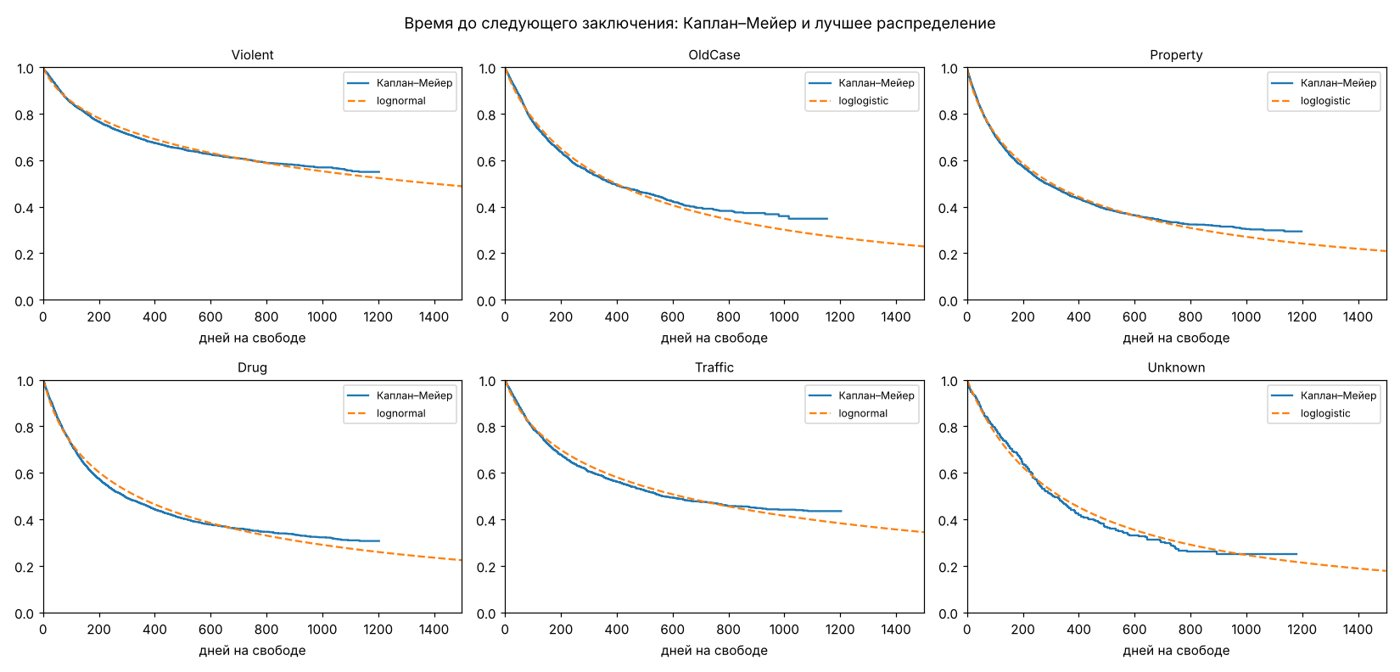

,n,events,km_median,S(365),S(730),weibull_rho,best,best_median
state,,,,,,,,
Violent,4620,1811,inf,0.687,0.603,0.621,lognormal,1390.9
OldCase,3846,1855,383.0,0.509,0.391,0.739,loglogistic,395.4
Property,3845,2423,283.0,0.450,0.334,0.641,loglogistic,302.9
Drug,3559,2216,291.0,0.462,0.357,0.661,lognormal,335.1
Traffic,2438,1245,563.0,0.575,0.473,0.646,lognormal,625.3
Unknown,581,309,309.0,0.449,0.293,0.802,loglogistic,331.3
ResistPolice,579,353,301.0,0.465,0.358,0.636,lognormal,333.9
Fraud,554,297,484.0,0.552,0.438,0.653,loglogistic,536.4
PublicOrder,304,222,146.0,0.305,0.228,0.622,lognormal,147.1


In [40]:
state_dist, state_fits = ST.fit_state_distributions(E)
state_dist.to_csv(OUT23 / "state_time_distributions.csv")
top_states = list(state_dist.index[:6])
ST.plot_state_fits(state_fits, FIG23 / "state_time_fits.png", top_states,
                   "Время до следующего заключения: Каплан–Мейер и лучшее распределение")
show(FIG23 / "state_time_fits.png")
state_dist[["n", "events", "km_median", "S(365)", "S(730)", "weibull_rho", "best", "best_median"]]

**Как читать.** `km_median` — медиана Каплана–Мейера (дни; `inf` — больше половины не вернулись до конца
наблюдения), `S(365)` и `S(730)` — доля не вернувшихся за 1 и 2 года, `weibull_rho` — форма Вейбулла,
`best` — распределение с минимальным AIC и его медиана. Значения AIC всех распределений — в CSV.

### 2.4. Полумарковская модель: распределение времени на дуге

В полумарковской модели процесс задаётся двумя частями: вероятностями $p_{ij}$ (2.1) и распределением
времени $F_{ij}(t)$ при условии, что произошёл именно переход $i \to j$. Для дуг с не менее 30 переходами
подбираются Вейбулл, логнормальное и лог-логистическое распределения (только наблюдавшиеся переходы, без
цензуры), лучшее — по AIC. Условные распределения на дугах обычно с $\rho \approx 1$: падающий риск
в 2.3 получается в основном из-за смеси людей, которые вернутся, и тех, кто не вернётся.

In [41]:
arc_dist = ST.fit_arc_distributions(E)
arc_dist.to_csv(OUT23 / "arc_time_distributions.csv", index=False)
print("лучшее распределение на дугах:", arc_dist["best"].value_counts().to_dict())
print("доля дуг с формой Вейбулла rho < 1:", round(float((arc_dist["weibull_rho"] < 1).mean()), 3))
arc_dist.head(20)

лучшее распределение на дугах: {'weibull': 54, 'lognormal': 1, 'loglogistic': 1}
доля дуг с формой Вейбулла rho < 1: 0.482


,from,to,n,median_days,weibull_lambda,weibull_rho,best_median,best
0,OldCase,OldCase,993,104.0,150.6,1.038,105.8,weibull
1,Property,OldCase,860,138.0,206.9,1.014,144.1,weibull
2,Drug,OldCase,830,128.0,191.8,1.061,135.8,weibull
3,Property,Property,762,80.0,129.5,0.838,83.6,weibull
4,Drug,Drug,576,111.5,162.5,0.936,109.8,weibull
5,Violent,OldCase,563,133.0,199.0,0.979,136.9,weibull
6,Violent,Violent,482,133.0,197.8,0.924,133.0,weibull
7,Traffic,OldCase,386,140.0,200.6,1.082,143.0,weibull
8,Traffic,Traffic,313,138.0,200.1,0.979,137.6,weibull
9,Drug,Property,247,94.0,145.8,0.926,98.1,weibull


### 2.5. Конкурирующие риски: вероятность перейти в $j$ за $t$ дней

Из состояния $i$ человек может попасть в любое из состояний $j$ — это конкурирующие риски; цензура —
конец наблюдения. Оценка Аалена–Йохансена даёт кумулятивную функцию инцидентности
$\mathrm{CIF}_{ij}(t) = P(T \le t,\ K = j \mid i)$ — вероятность, что следующим будет заключение типа $j$ и
случится не позже $t$. В отличие от $p_{ij}$, она учитывает время и цензуру; сумма по $j$ — вероятность
любого нового заключения за $t$ (линия «любое» $= 1 - S(t)$ из 2.3). Таблица — для состояний с не менее
200 заключениями на горизонтах 90, 180, 365, 730 дней.

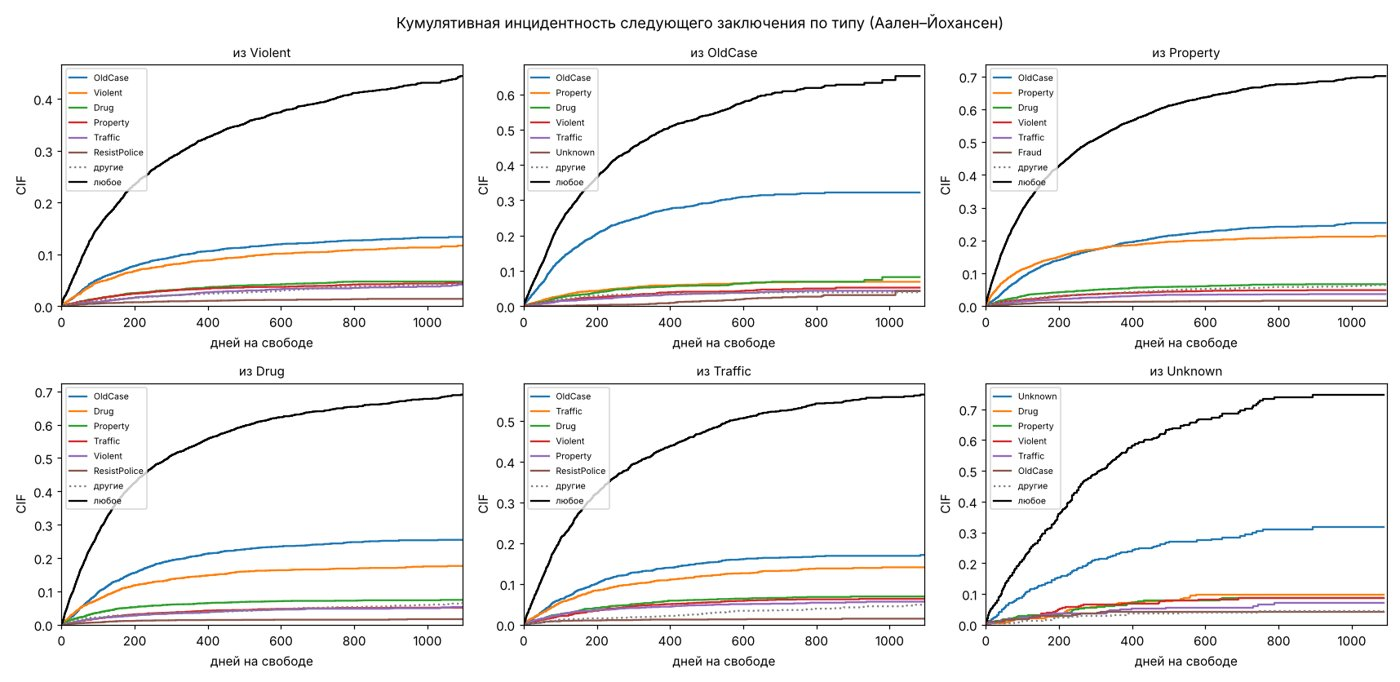

to,любое,OldCase,Property,Drug,Violent,Traffic,Unknown,ResistPolice,Fraud
from,,,,,,,,,
Violent,0.313,0.103,0.032,0.035,0.087,0.024,0.003,0.010,0.007
OldCase,0.491,0.268,0.059,0.054,0.037,0.030,0.008,0.014,0.006
Property,0.550,0.190,0.183,0.053,0.040,0.030,0.004,0.011,0.013
Drug,0.538,0.205,0.063,0.144,0.035,0.040,0.003,0.014,0.008
Traffic,0.425,0.137,0.043,0.055,0.049,0.108,0.001,0.012,0.008
Unknown,0.551,0.041,0.064,0.070,0.066,0.046,0.234,0.005,0.002
ResistPolice,0.535,0.140,0.096,0.070,0.090,0.045,0.004,0.034,0.016
Fraud,0.448,0.200,0.085,0.041,0.031,0.037,0.000,0.011,0.032
PublicOrder,0.695,0.115,0.238,0.086,0.090,0.035,0.000,0.020,0.014


In [42]:
cif, cif_curves = ST.cumulative_incidence(E)
cif.to_csv(OUT23 / "cif_competing_risks.csv", index=False)
cif_states = list(cif_curves)[:6]
ST.plot_cif(cif_curves, FIG23 / "cif_top_states.png", cif_states,
            "Кумулятивная инцидентность следующего заключения по типу (Аален–Йохансен)")
show(FIG23 / "cif_top_states.png")
# вероятность за 1 год: строки — откуда, столбцы — куда (самые частые направления)
cif_1y = cif.pivot(index="from", columns="to", values="CIF_365d")
cols = ["любое"] + [c for c in cif[cif["to"] != "любое"].groupby("to")["events"].sum().sort_values(ascending=False).index[:8]]
cif_1y.reindex(index=[s for s in ST.state_order(E) if s in cif_1y.index], columns=cols).round(3)

## Этап 3. Признаки объекта и события, модели выживаемости между состояниями

Признаки (в моделях берутся строки с известным временем на свободе и баллом COMPAS):

| признак | что это | тип |
|---|---|---|
| `age10` | возраст на дату оценки COMPAS, на 10 лет (HR — на каждые 10 лет) | объект |
| `male` | мужчина | объект |
| `race_afam`, `race_other` | афроамериканец; другая раса (Hispanic, Asian, Native American, Other); база — Caucasian | объект |
| `score` | исходный балл COMPAS `decile_score` (1–10, риск рецидива) | объект |
| `felony` | самое тяжёлое обвинение заключения — фелония | событие |
| `n_charges` | число обвинений в заключении (до 10) | событие |
| `log_dur` | $\log(1 + \text{дней в заключении})$ | событие |
| `prior_eps` | сколько заключений было у человека раньше (до 5) | событие |
| `old_case` | в заключении есть обвинение по делу из прежнего заключения (нет у данных Даши) | событие |

Признаки объекта не меняются во времени. Балл COMPAS и возраст взяты на дату оценки COMPAS, которая для
части заключений позже их начала, — это свойство данных ProPublica (одна оценка на человека).
Люди делятся на train 80% / test 20% (seed 42), C-index (согласованность прогноза риска и времени;
0.5 — случайно, 1 — идеально) считается на test.

In [43]:
feats = ST.features_of(E)
R = ST.model_frame(E, feats)
train23, test23 = ST.split_people(R)
print("признаки:", feats)
print(f"строк для моделей: {len(R):,} (train {len(train23):,}, test {len(test23):,}); "
      f"событий в train: {int(train23['event'].sum()):,}")
R[feats].describe().T[["mean", "std", "min", "max"]].round(3)

признаки: ['age10', 'male', 'race_afam', 'race_other', 'score', 'felony', 'n_charges', 'log_dur', 'prior_eps', 'old_case']
строк для моделей: 21,067 (train 16,763, test 4,304); событий в train: 8,820


,mean,std,min,max
age10,3.368,1.141,1.8,9.600
male,0.817,0.387,0.0,1.000
race_afam,0.544,0.498,0.0,1.000
race_other,0.126,0.332,0.0,1.000
score,5.227,2.936,1.0,10.000
felony,0.642,0.480,0.0,1.000
n_charges,2.754,2.150,1.0,10.000
log_dur,1.985,1.668,0.0,7.085
prior_eps,1.023,1.355,0.0,5.000
old_case,0.255,0.436,0.0,1.000


### 3.1. CoxPH: время до следующего заключения любого типа

Модель пропорциональных рисков Кокса, **стратифицированная по текущему состоянию**: у каждого состояния свой
базовый риск $h_{0,i}(t)$, а признаки действуют одинаково, $h(t \mid i, x) = h_{0,i}(t)\, e^{\beta^\top x}$.
$\mathrm{HR} = e^\beta$ — во сколько раз признак меняет риск нового заключения (HR > 1 — возвращаются
быстрее). Ниже — сравнение C-index на test для моделей «только состояние», «только признаки»,
«состояние + признаки» (состояние — индикаторами, база — первое по алфавиту; состояния реже 30 заключений
в train остаются в базе) и HR состояний из последней модели.

In [44]:
cph, cox_hr, cox_cindex, cox_state_hr = ST.cox_any(train23, test23, feats)
cox_hr.to_csv(OUT23 / "cox_any_hr.csv")
cox_cindex.to_csv(OUT23 / "cox_cindex_test.csv", header=["c_index"])
cox_state_hr.to_csv(OUT23 / "cox_state_hr.csv")
print("C-index на test:")
print(cox_cindex.to_string())
cox_hr

C-index на test:
только состояние        0.5781
только признаки         0.6694
состояние + признаки    0.6750


,признак,HR,HR 95% низ,HR 95% верх,p
covariate,,,,,
age10,возраст (на 10 лет),0.986,0.966,1.006,0.1717
male,мужчина,1.234,1.165,1.306,0.0000
race_afam,афроамериканец,0.997,0.950,1.046,0.9010
race_other,др. раса (не белый),0.868,0.805,0.936,0.0002
score,балл COMPAS (decile),1.166,1.156,1.177,0.0000
felony,фелония,0.921,0.874,0.971,0.0022
n_charges,число обвинений,1.003,0.992,1.014,0.6214
log_dur,log длит. заключения,0.989,0.975,1.003,0.1346
prior_eps,заключений до этого,1.123,1.103,1.143,0.0000


In [45]:
# HR текущего состояния (модель «состояние + признаки»; база — первое по алфавиту состояние)
cox_state_hr.sort_values("HR")

,HR,p
Violent,0.6538,0.0000
Tampering,0.7282,0.0027
OldCase,0.8186,0.0001
Unknown,0.8313,0.0112
Traffic,0.8908,0.0044
Weapon,0.9171,0.3643
ResistPolice,0.9668,0.6019
Fraud,0.9740,0.6988
Sex,0.9749,0.8092
Property,1.0924,0.0067


### 3.2. Модели Кокса по дугам (причинно-специфичные риски)

Влияние признаков на **конкретный переход** $i \to j$: для людей в состоянии $i$ событие — следующее
заключение типа $j$, переходы в другие типы и конец наблюдения — цензура. Такая модель
причинно-специфичного риска $h_{ij}(t \mid x) = h_{0,ij}(t)\, e^{\beta_{ij}^\top x}$ — стандартный способ
оценивать признаки при конкурирующих рисках. Модели строятся на всех людях для дуг с не менее
`MIN_ARC_EVENTS` переходами (лёгкая L2-регуляризация, penalizer = 0.05, иначе на редких дугах коэффициенты
расходятся). Признак, постоянный внутри состояния, выпадает.

In [46]:
arc_cox = ST.cox_arcs(R, feats, min_events=MIN_ARC_EVENTS)
arc_cox.to_csv(OUT23 / "cox_arcs_hr.csv", index=False)
arc_effects = ST.arc_effects_summary(arc_cox, feats)
arc_effects.to_csv(OUT23 / "cox_arcs_feature_summary.csv")
print(f"дуг с моделью: {arc_cox['arc'].nunique()}")
arc_effects

дуг с моделью: 43


,дуг,HR>1 значимо,HR<1 значимо,медиана HR,мин HR,макс HR
возраст (на 10 лет),43,1,6,0.960,0.826,1.117
мужчина,43,7,0,1.136,0.512,1.996
афроамериканец,43,4,0,1.050,0.756,1.575
др. раса (не белый),43,0,4,0.912,0.474,1.679
балл COMPAS (decile),43,34,0,1.086,1.027,1.158
фелония,42,4,11,0.888,0.552,1.986
число обвинений,43,3,0,0.995,0.818,1.082
log длит. заключения,43,5,4,0.993,0.915,1.129
заключений до этого,43,15,0,1.061,0.922,1.276
старое дело в заключении,35,1,1,0.926,0.460,2.306


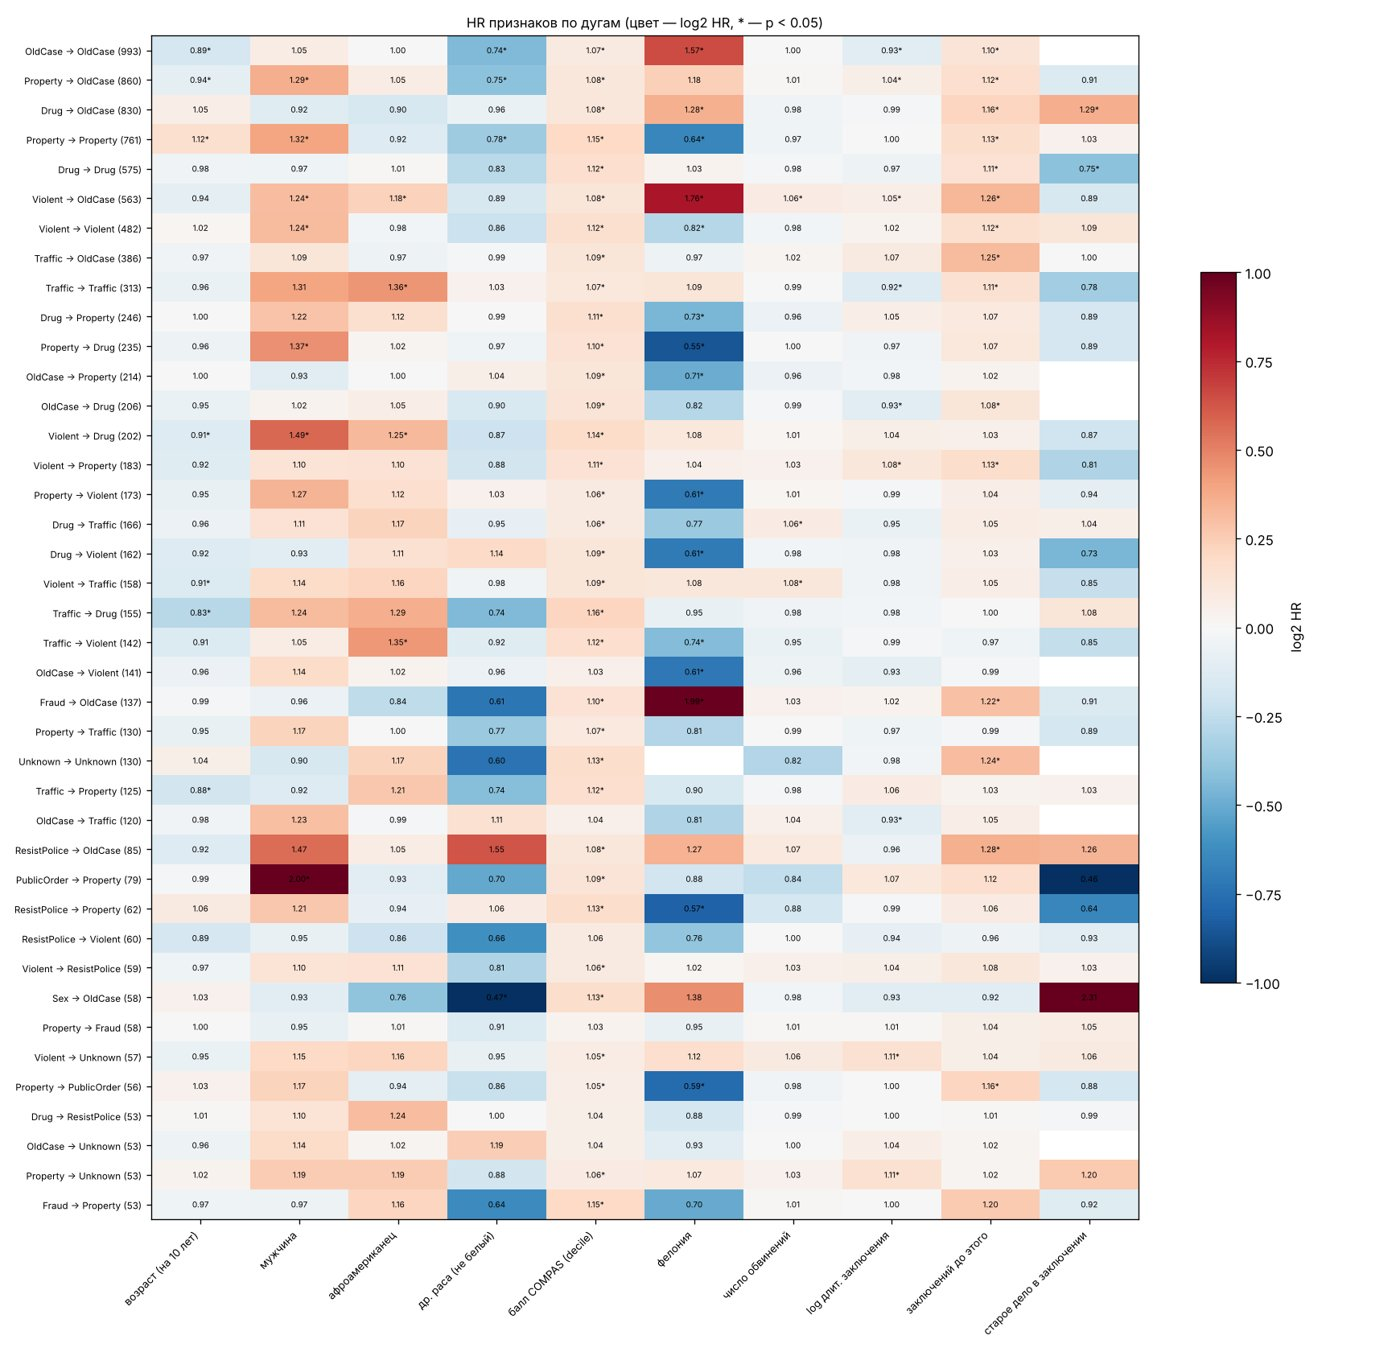

In [47]:
ST.plot_arc_heatmap(arc_cox, feats, FIG23 / "cox_arcs_heatmap.png",
                    "HR признаков по дугам (цвет — log2 HR, * — p < 0.05)")
show(FIG23 / "cox_arcs_heatmap.png")

**Как читать.** Таблица: на скольких дугах признак значимо (p < 0.05) ускоряет (HR > 1) или замедляет
(HR < 1) переход, медиана и размах HR. Тепловая карта — самые частые дуги (в скобках число переходов):
красное — признак ускоряет именно этот переход, синее — замедляет. Признак, который ускоряет одни переходы
и замедляет другие, меняет не только «скорость возвращения», но и **тип** следующего заключения.
Все HR и доверительные интервалы — в `cox_arcs_hr.csv`.

### 3.3. Дерево выживаемости

Дерево выживаемости (scikit-survival, разбиения по log-rank) для времени до следующего заключения: признаки
+ текущее состояние. Глубина 3, в листе не меньше 300 заключений, чтобы дерево читалось. Листья
отсортированы от самого быстрого возвращения: `km_median` — медиана Каплана–Мейера в листе, `S365` — доля
не вернувшихся за год. Ниже — кривые Каплана–Мейера листьев.

C-index дерева на test: 0.6548


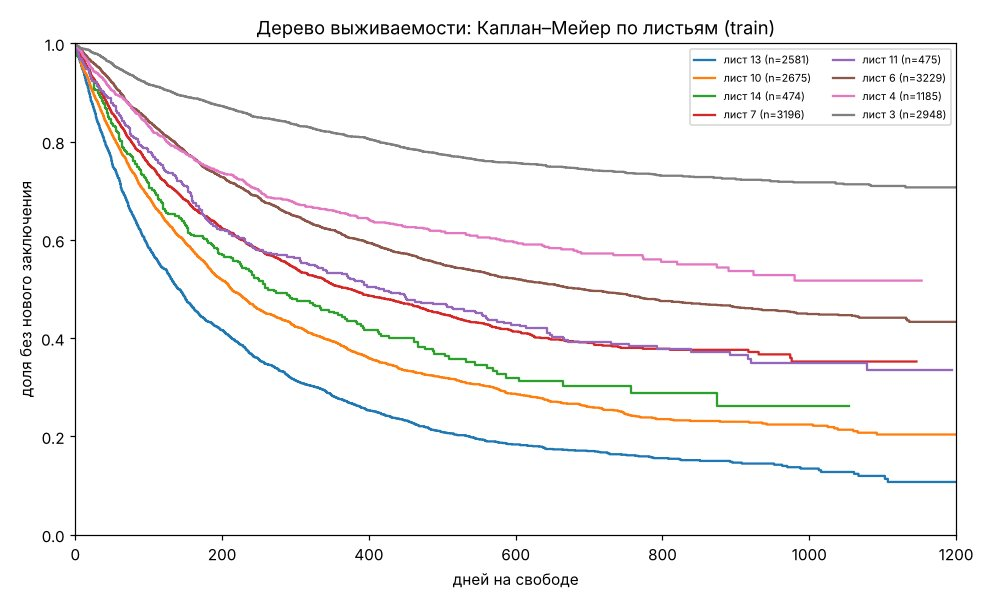

,leaf,path,n,events,km_median,S365
0,13,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,2581,1976,141.0,0.273
1,10,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,2675,1787,213.0,0.384
2,14,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,474,264,263.0,0.443
3,7,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,3196,1619,375.0,0.503
4,11,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,475,275,414.0,0.530
5,6,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,3229,1682,690.0,0.610
6,4,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,1185,431,inf,0.655
7,3,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,2948,786,inf,0.815


In [48]:
tree23, leaves23, tree_c = ST.survival_tree(train23, test23, feats)
leaves23.to_csv(OUT23 / "survival_tree_leaves.csv", index=False)
print(f"C-index дерева на test: {tree_c:.4f}")
ST.plot_tree_leaves(train23, tree23, feats, leaves23, FIG23 / "survival_tree_leaves.png",
                    "Дерево выживаемости: Каплан–Мейер по листьям (train)")
show(FIG23 / "survival_tree_leaves.png")
leaves23

### 3.4. Случайный лес выживаемости и важность признаков

Random Survival Forest (100 деревьев, лист от 50 заключений) — нелинейная модель для сравнения с Коксом.
Важность признака — насколько падает C-index на test, если перемешать этот признак (текущее состояние
перемешивается целиком). Флаг `RUN_RSF = False` пропускает этот шаг.

In [49]:
if RUN_RSF:
    rsf_c, rsf_imp, rsf_sec = ST.random_forest(train23, test23, feats)
    rsf_imp.to_csv(OUT23 / "rsf_permutation_importance.csv", header=["drop_in_c_index"])
    print(f"RSF: C-index на test {rsf_c:.4f} ({rsf_sec} с)")
    display(rsf_imp.to_frame("падение C-index"))
else:
    rsf_c, rsf_imp = float("nan"), pd.Series(dtype=float)

cindex_all = pd.concat([cox_cindex.rename(lambda s: "Кокс: " + s),
                        pd.Series({"дерево выживаемости": round(tree_c, 4), "случайный лес": round(rsf_c, 4)})])
cindex_all.to_csv(OUT23 / "cindex_all_models.csv", header=["c_index"])
ST.save_excel(OUT23 / "stage23_tables.xlsx", {
    "сводка": ST.episodes_summary(E).to_frame("значение"), "переходы_число": cnt, "переходы_p": P.round(4),
    "переходы_сводка": trans_summary, "время_дуги": arcs23, "время_состояния": state_dist,
    "распр_дуги": arc_dist, "CIF": cif, "cox_hr": cox_hr, "cox_состояния": cox_state_hr,
    "cox_дуги": arc_cox, "cox_дуги_сводка": arc_effects, "дерево_листья": leaves23,
    "rsf_важность": rsf_imp.to_frame("падение C-index"), "c_index": cindex_all.to_frame("c_index")})
cindex_all.to_frame("C-index (test)")

RSF: C-index на test 0.6784 (7 с)


,падение C-index
балл COMPAS (decile),0.0978
заключений до этого,0.0145
текущее состояние,0.0138
log длит. заключения,0.0061
мужчина,0.0025
фелония,0.0024
старое дело в заключении,0.0010
др. раса (не белый),0.0005
число обвинений,0.0003
афроамериканец,0.0002


таблицы: /tmp/claude-0/w/jl/stage1/oldcase/notebook_out/stage23/stage23_tables.xlsx


,C-index (test)
Кокс: только состояние,0.5781
Кокс: только признаки,0.6694
Кокс: состояние + признаки,0.6750
дерево выживаемости,0.6548
случайный лес,0.6784


## Итоги этапов 2–3 (15 категорий + OldCase)

**Этап 2. Параметры переходов.** 21 716 заключений, 15 состояний (OldCase — заключение только по старым делам,
4 070 заключений), 11 136 переходов.
- Вероятности: петли новых категорий 0.25–0.31 (вместо 0.57–0.68 в all_new), OldCase → OldCase 0.54;
  в OldCase чаще всего ведут Property (860 переходов), Drug (830), Violent (563).
- Время на свободе: OldCase → OldCase медиана 104 дня, X → OldCase 128–140 дней, Property → Property 80.
  За год после OldCase возвращаются 49%, после Violent 31%, после Property и Drug 54–55%.
  Форма Вейбулла ρ = 0.57–0.80, у OldCase 0.74.

**Этап 3. Признаки.** Кокс по состояниям: балл COMPAS 1.166, предыдущее заключение 1.12, мужчина 1.23,
другая раса 0.87, фелония 0.92; старое дело — на границе (0.92, p = 0.05).
- HR состояний (база — Drug вместе с редкими состояниями): Violent 0.65, Tampering 0.73, OldCase 0.82 — медленнее;
  Property 1.09, PublicOrder 1.30 — быстрее.
- C-index на test: только состояние 0.578, только признаки 0.669, вместе 0.675, дерево 0.655, лес 0.678.
- По 43 дугам: балл ускоряет 34; фелония сильнее всего ускоряет переходы в OldCase
  (Fraud → OldCase 2.0, Violent → OldCase 1.8, OldCase → OldCase 1.6), то есть после фелонии человек чаще
  возвращается в заключение по тому же делу; смену типа фелония замедляет (Property → Drug 0.55).
  Прошлые заключения тоже ускоряют именно переходы в OldCase (HR 1.25–1.28).

**Сравнение кейсов** (C-index на test; Кокс «состояние + признаки» / только состояние / случайный лес):
эксп. 1 — 0.674 / 0.576 / 0.678; эксп. 3 — 0.675 / 0.577 / 0.678; данные Даши — 0.679 / 0.575 / 0.678;
15 категорий all_new — 0.674 / 0.572 / 0.677; oldcase — 0.675 / 0.578 / 0.678. Во всех кейсах картина одна:
скорость возвращения определяют в основном признаки человека, а тип текущего заключения добавляет немного;
зато тип влияет на то, **куда** человек перейдёт (матрица переходов, CIF и модели по дугам).

**Ограничения.** Балл COMPAS и возраст взяты на дату оценки COMPAS (одна на человека), для части заключений она
позже их начала. HR в моделях по дугам — без поправки на множественные сравнения (много дуг × 10 признаков),
поэтому одиночные значимые HR на редких дугах — ориентиры, а не выводы. Пропорциональность рисков не
проверялась формально; дерево и лес её не требуют и дают близкий C-index.
